# Libraries & path

In [2]:
%cd C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis
# %cd D:\2022_deep_music\maestro_analysis

C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis


In [3]:
import os
from pathlib import Path
import pickle
import copy
import mat73

import matplotlib
import matplotlib.pyplot as plt
# %matplotlib ipympl
# plt.switch_backend('TkAgg')
import numpy as np
import pandas as pd
import scipy
import mne

from sklearn.decomposition import PCA, FastICA, NMF
from maestro_analysis.note_analysis import regression_predictive_features, custom_spatio_temporal_cluster_regression_scores_seeg
from maestro_analysis.utils import plot_seeg, plot_seeg_gridspec

c:\ProgramData\mne-python\1.1.1_0\lib\site-packages\cupy\_environment.py:213: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(
c:\ProgramData\mne-python\1.1.1_0\lib\site-packages\outdated\utils.py:14: OutdatedPackageWarning: The package pingouin is out of date. Your version is 0.5.2, the latest is 0.5.3.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(
c:\ProgramData\mne-python\1.1.1_0\lib\site-packages\outdated\utils.py:14: OutdatedPackageWarning: The package outdated is out of date. Your version is 0.2.1, the latest is 0.2.2.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(


# Load or compute regression

In [23]:
path = 'D:/2022_deep_music/seeg/'
fs_path = path + 'freesurfer/'
epochs_path = path + 'epochs_note_level/'
save_path = path + 'regression_note_level/'
model = 'paulrnn'

# compute reg
# reg_paulrnn = regression_predictive_features(epochs_path, save_path, 
#                                     confounds='all', model='paulrnn', data_type='seeg',
#                                     signal_type='raw', montage='mono', specific_channels=None, add_shifted=True, tmin=2, tmax=7,
#                                     n_folds=5, alphas=(1e2, 1e3, 1e4, 1e5, 1e6, 1e7), permutation=False, r2_control=None,
#                                     min_time_interval=0.050, best_channels_path=None, deviation_quantile_range=None, baseline=False)
# reg_mperfrnn = regression_predictive_features(epochs_path, save_path, 
#                                     confounds='all', model='magenta_perfrnn', data_type='seeg',
#                                     signal_type='raw', montage='mono', specific_channels=None, add_shifted=True, tmin=2, tmax=7,
#                                     n_folds=5, alphas=(1e2, 1e3, 1e4, 1e5, 1e6, 1e7), permutation=False, r2_control=None,
#                                     min_time_interval=0.050, best_channels_path=None, deviation_quantile_range=None, baseline=False)
# reg_acoustic = regression_predictive_features(epochs_path, save_path, 
#                                     confounds='all', model=None, data_type='seeg',
#                                     signal_type='raw', montage='mono', specific_channels=None, add_shifted=True, tmin=2, tmax=7,
#                                     n_folds=5, alphas=(1e2, 1e3, 1e4, 1e5, 1e6, 1e7), permutation=False, r2_control=None,
#                                     min_time_interval=0.050, best_channels_path=None, deviation_quantile_range=None, baseline=False)

#load reg
with open(save_path + 'regr_seeg_raw_mono_paulrnn.pkl', 'rb') as fp:
    reg_paulrnn = pickle.load(fp) 
with open(save_path + 'regr_seeg_raw_mono_magenta_perfrnn.pkl', 'rb') as fp:
    reg_mperfrnn = pickle.load(fp) 
with open(save_path + 'regr_seeg_raw_mono_acoustic.pkl', 'rb') as fp:
    reg_acoustic = pickle.load(fp)

#retrieve times and feature list
times = reg_paulrnn[list(reg_acoustic.keys())[0]]['times']
features = reg_paulrnn[list(reg_acoustic.keys())[0]]['features']
print(features)
print(len(features))

['rate', 'trial_time', 'time_interval', 'pitch', 'pitch_interval', 'loudness', 'brightness', 'periodicity', 'roughness', 'spectralflux', 'loudness_deriv', 'brightness_deriv', 'periodicity_deriv', 'roughness_deriv', 'spectralflux_deriv', 'shifted_trial_time', 'shifted_time_interval', 'shifted_pitch', 'shifted_pitch_interval', 'shifted_loudness', 'shifted_brightness', 'shifted_periodicity', 'shifted_roughness', 'shifted_spectralflux', 'shifted_loudness_deriv', 'shifted_brightness_deriv', 'shifted_periodicity_deriv', 'shifted_roughness_deriv', 'shifted_spectralflux_deriv', 'surprise_mean_paulrnn', 'entropy_pitch_paulrnn', 'entropy_timing_paulrnn', 'shifted_surprise_mean_paulrnn', 'shifted_entropy_pitch_paulrnn', 'shifted_entropy_timing_paulrnn']
35


# Compute regression for variance partitioning

In [4]:
path = 'D:/2022_deep_music/seeg/'
fs_path = path + 'freesurfer/'
epochs_path = path + 'epochs_note_level/'
vp_path = path + 'regression_note_level/variance_partitioning_/'

if not os.path.exists(save_path):
    os.makedirs(save_path)

features = ['surprise_mean_paulrnn', 'shifted_surprise_mean_paulrnn',
            'entropy_pitch_paulrnn', 'shifted_entropy_pitch_paulrnn',
            'entropy_timing_paulrnn', 'shifted_entropy_timing_paulrnn']

for feat in features:
    regression_predictive_features(epochs_path, vp_path, 
                                confounds='all', model='paulrnn', data_type='seeg',
                                signal_type='raw', montage='mono', specific_channels=None, add_shifted=True, remove = [feat],
                                tmin=2, tmax=7,n_folds=5, alphas=(1e2, 1e3, 1e4, 1e5, 1e6, 1e7), 
                                permutation=False, r2_control=None,min_time_interval=0.050, 
                                best_channels_path=None, deviation_quantile_range=None, baseline=False)

Bou_Al_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\note_analysis.py:1091: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 46 columns
Regression took 54.57674169540405 seconds
Bou_Ni_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\note_analysis.py:1091: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
5437 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 5437
Number of notes after min_time_interval: 3470
Replacing existing metadata with 46 columns
Regression took 33.51291108131409 seconds
Dav_To_epochs_mono_preprocessed_IDA.fif


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\note_analysis.py:1091: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


Reading D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif ...
    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 46 columns
Regression took 53.44102883338928 seconds
Dri_Am_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\note_analysis.py:1091: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10764 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10764
Number of notes after min_time_interval: 6945
Replacing existing metadata with 46 columns
Regression took 72.31691288948059 seconds
Gra_Lu_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\note_analysis.py:1091: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 46 columns
Regression took 66.2539291381836 seconds
Pen_Va_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\note_analysis.py:1091: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
8671 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 8671
Number of notes after min_time_interval: 5648
Replacing existing metadata with 46 columns
Regression took 50.222816705703735 seconds
Sou_Fa_epochs_mono_preprocessed_IDA.fif


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\note_analysis.py:1091: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


Reading D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif ...
    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 46 columns
Regression took 58.99080944061279 seconds
The_Mo_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\note_analysis.py:1091: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 46 columns
Regression took 55.34266662597656 seconds
Tou_Et_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\note_analysis.py:1091: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 46 columns
Regression took 61.05848002433777 seconds
Tou_Ma_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\note_analysis.py:1091: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 46 columns
Regression took 68.94433689117432 seconds
Bou_Al_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\note_analysis.py:1091: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


# Compute statistics

In [25]:
model = 'paulrnn' #paulrnn, magenta_perfrnn
regression_pkl = save_path + 'regr_seeg_raw_mono_'+model+'.pkl'
control_pkl = save_path + 'regr_seeg_raw_mono_acoustic.pkl'
permutation_folder = path + 'permutations/permut_03_11_23/' #using paulrnn permut with 3 features of interest
out_folder = save_path + 'perm_results/'
cluster_thresh = 0.005

cluster_file = out_folder + 'c_' + str(cluster_thresh).split('.')[1] + '/clusters_' + str(cluster_thresh).split('.')[1] + '.pkl'
if os.path.isfile(cluster_file):
    with open(cluster_file, 'rb') as handle:
        clusters = pickle.load(handle)
        c_sign = clusters['clusters_sign']
        ch_sign = clusters['channels_sign']
        ch_sign_sub = clusters['channels_sign_sub']

        #names of all channels
        all_ch = []
        for sub in reg_acoustic.keys():
            for ch in reg_acoustic[sub]['ch_names']:
                all_ch.append(sub+'_'+ch)
        all_ch = np.array(all_ch)
        print(all_ch[ch_sign])
else:
    c_sign, ch_sign = custom_spatio_temporal_cluster_regression_scores_seeg(model,regression_pkl, control_pkl, permutation_folder, cluster_thresh, out_folder)
    # ch_sign

    #names of all channels
    all_ch = []
    for sub in reg_acoustic.keys():
        for ch in reg_acoustic[sub]['ch_names']:
            all_ch.append(sub+'_'+ch)
    all_ch = np.array(all_ch)

    print(all_ch[ch_sign])

    #indexes of sign channels for each subject
    ch_sign_sub = []
    min_idx = 0
    for i, sub in enumerate(reg_acoustic.keys()):
        ch_sign_sub.append([])
        for ch in ch_sign:
            if ch >= min_idx and ch < min_idx+len(reg_acoustic[sub]['ch_names']):
                ch_sign_sub[i].append(ch-min_idx)
        min_idx += len(reg_acoustic[sub]['ch_names'])

    out = {'clusters_sign':c_sign, 'channels_sign':ch_sign, 'channels_sign_sub':ch_sign_sub}
    with open(cluster_file, 'wb') as handle:
        pickle.dump(out, handle)

["Bou_Al_Ip'1" 'Bou_Ni_H6' 'Bou_Ni_H7' 'Bou_Ni_H8' 'Bou_Ni_H9'
 'Bou_Ni_H10' 'Bou_Ni_H11' 'Bou_Ni_H12' "Bou_Ni_H'8" "Bou_Ni_H'9"
 "Dav_To_H'8" "Dav_To_H'9" "Dav_To_H'10" 'Dri_Am_H6' 'Gra_Lu_H12'
 'Gra_Lu_H13' "Pen_Va_H'12" "Pen_Va_H'13" "Pen_Va_A'12" "Pen_Va_B'6"
 "Pen_Va_B'7" "Pen_Va_B'8" "Pen_Va_B'9" 'The_Mo_T1' 'The_Mo_H3'
 'The_Mo_H4' 'The_Mo_H5' 'The_Mo_H6' 'The_Mo_H7' 'The_Mo_GC12'
 "Tou_Et_H'8" "Tou_Et_H'9"]


In [10]:
#If no stats, take all ch
all_ch = []
for sub in reg_acoustic.keys():
    for ch in reg_acoustic[sub]['ch_names']:
        all_ch.append(sub+'_'+ch)
ch_sign = np.arange(len(all_ch))

#indexes of sign channels for each subject
ch_sign_sub = []
min_idx = 0
for i, sub in enumerate(reg_acoustic.keys()):
    ch_sign_sub.append([])
    for ch in ch_sign:
        if ch >= min_idx and ch < min_idx+len(reg_acoustic[sub]['ch_names']):
            ch_sign_sub[i].append(ch-min_idx)
    min_idx += len(reg_acoustic[sub]['ch_names'])

In [20]:
#If no stats, take all ch with a peak treshold
r2_thresh = 0.005

ch_sign = []
i_ch = 0
for sub in reg_acoustic.keys():
    for sub_ch, ch in enumerate(reg_acoustic[sub]['ch_names']):
        # if np.max(reg_paulrnn[sub]['subject_r2'][sub_ch,:] - reg_acoustic[sub]['subject_r2'][sub_ch,:]) > r2_thresh:
        if np.max(reg_mperfrnn[sub]['subject_r2'][sub_ch,:] - reg_acoustic[sub]['subject_r2'][sub_ch,:]) > r2_thresh:
            ch_sign.append(i_ch)
        i_ch += 1
ch_sign = np.array(ch_sign)

#indexes of sign channels for each subject
ch_sign_sub = []
min_idx = 0
for i, sub in enumerate(reg_acoustic.keys()):
    ch_sign_sub.append([])
    for ch in ch_sign:
        if ch >= min_idx and ch < min_idx+len(reg_acoustic[sub]['ch_names']):
            ch_sign_sub[i].append(ch-min_idx)
    min_idx += len(reg_acoustic[sub]['ch_names'])

# Retrieving ROIs

## Desikan-Killiany

 Large ROIs from atlas (standard aparc+aseg in fsaverage)

In [199]:
all_channels = []
ROI_labels_auditory = ['transversetemporal', 'superiortemporal', 'middletemporal', 'inferiortemporal', 'temporalpole' ]
ROI_labels_frontal = ['superiorfrontal', 'rostralmiddlefrontal', 'parstriangularis', 'parsorbitalis', 'parsopercularis',
                       'medialorbitofrontal', 'lateralorbitofrontal', 'frontalpole', 'caudalmiddlefrontal']
ROI_exclusion = []

ROI_idx_auditory = []
ROI_idx_frontal = []
i_ch=0
montage = []
for sub in reg_acoustic.keys():
    print(sub)

    montage = reg_acoustic[sub]['montage']
    head_mri = mne.transforms.Transform(fro="head", to="mri", trans=np.eye(4))
    # montage.apply_trans(head_mri)
    try:
        labels, _ = mne.get_montage_volume_labels(montage, 'fsaverage', subjects_dir=fs_path, aseg='aparc+aseg', dist=3)
    except:
        montage.apply_trans(head_mri)
        labels, _ = mne.get_montage_volume_labels(montage, 'fsaverage', subjects_dir=fs_path, aseg='aparc+aseg', dist=3)

    for ch in labels.keys():
        all_channels.append(ch)
        if sum([roi in l for l in labels[ch] for roi in ROI_labels_auditory]) > 0:
            ROI_idx_auditory.append(i_ch)
        if sum([roi in l for l in labels[ch] for roi in ROI_labels_frontal]) > 0:
            ROI_idx_frontal.append(i_ch)
        i_ch += 1

#indexes for each subject
ROI_idx_auditory_sub = []
ROI_idx_frontal_sub = []
min_idx = 0
for i, sub in enumerate(reg_acoustic.keys()):
    ROI_idx_auditory_sub.append([])
    ROI_idx_frontal_sub.append([])
    for ch in ROI_idx_auditory:
        if ch >= min_idx and ch < min_idx+len(reg_acoustic[sub]['ch_names']):
            ROI_idx_auditory_sub[i].append(ch-min_idx)
    for ch in ROI_idx_frontal:
        if ch >= min_idx and ch < min_idx+len(reg_acoustic[sub]['ch_names']):
            ROI_idx_frontal_sub[i].append(ch-min_idx)
    min_idx += len(reg_acoustic[sub]['ch_names'])
        

Bou_Al
Bou_Ni
Dav_To
Dri_Am
Gra_Lu
Pen_Va
Sou_Fa
The_Mo
Tou_Et
Tou_Ma


Sub-ROIs

In [202]:
all_channels = []
ROI_labels_auditory = ['transversetemporal', 'superiortemporal', 'middletemporal', 'inferiortemporal', 'temporalpole' ]
ROI_exclusion = []

ROI_idx_auditory_list = []
i_ch=0
montage = []
for sub in reg_acoustic.keys():
    print(sub)

    montage = reg_acoustic[sub]['montage']
    head_mri = mne.transforms.Transform(fro="head", to="mri", trans=np.eye(4))
    # montage.apply_trans(head_mri)

    for il, roi_label in enumerate(ROI_labels_auditory):
        ROI_idx_auditory_list.append([])
        try:
            labels, _ = mne.get_montage_volume_labels(montage, 'fsaverage', subjects_dir=fs_path, aseg='aparc+aseg', dist=3)
        except:
            montage.apply_trans(head_mri)
            labels, _ = mne.get_montage_volume_labels(montage, 'fsaverage', subjects_dir=fs_path, aseg='aparc+aseg', dist=3)

        for ch in labels.keys():
            all_channels.append(ch)
            # [roi in l for l in labels[ch] for roi in ROI_labels_auditory]
            if sum([roi_label in l for l in labels[ch]]) > 0:
                ROI_idx_auditory_list[il].append(i_ch)
            i_ch += 1

# #indexes for each subject
ROI_idx_auditory_list_sub = []

for iL, roi_label in enumerate(ROI_labels_auditory):
    ROI_idx_auditory_list_sub.append([])
    min_idx = 0
    for iS, sub in enumerate(reg_acoustic.keys()):
        ROI_idx_auditory_list_sub[iL].append([])
        for ch in ROI_idx_auditory_list[iL]:
            if ch >= min_idx and ch < min_idx+len(reg_acoustic[sub]['ch_names']):
                ROI_idx_auditory_list_sub[iL][iS].append(ch-min_idx)
        min_idx += len(reg_acoustic[sub]['ch_names'])

Bou_Al
Bou_Ni
Dav_To
Dri_Am
Gra_Lu
Pen_Va
Sou_Fa
The_Mo
Tou_Et
Tou_Ma


## Brainnetome

In [5]:
## location of significant channels
for isub, sub in enumerate(reg_acoustic.keys()):
    print('-----', sub, isub)
    #retrieve labels from elec_recon
    elec_recon = mat73.loadmat(fs_path + sub + '/elec_recon/elec2atlas.mat')
    labels = {k[0]:v for k, v in zip(elec_recon['coi']['label'], elec_recon['Brainnetome']['label'])}
    #retrieve channel list from montage
    ch_list = reg_acoustic[sub]['montage'].ch_names

    for ch_idx in ch_sign_sub[isub]:
        ch = ch_list[ch_idx]
        try:
            labels[ch] = ['none' if l is None else l for l in labels[ch]]
            print(sub, '|', ch, '|', labels[ch][0].split(", ")[1])
        except:
            print(ch, ' is not in montage')

#names of all channels
all_ch = []
for sub in reg_acoustic.keys():
    for ch in reg_acoustic[sub]['ch_names']:
        all_ch.append(sub+'_'+ch)
all_ch = np.array(all_ch)

----- Bou_Al 0
Bou_Al | Ip'1 | Left Insular Gyrus G
----- Bou_Ni 1
Bou_Ni | H6 | Right Superior Temporal Gyrus TE1.0 and TE1.2
Bou_Ni | H7 | Right Superior Temporal Gyrus TE1.0 and TE1.2
Bou_Ni | H8 | Right Superior Temporal Gyrus TE1.0 and TE1.2
Bou_Ni | H9 | Right Superior Temporal Gyrus TE1.0 and TE1.2
Bou_Ni | H10 | Right Superior Temporal Gyrus TE1.0 and TE1.2
Bou_Ni | H11 | Right Superior Temporal Gyrus A41/42
Bou_Ni | H12 | Right Superior Temporal Gyrus A41/42
Bou_Ni | H'7 | Left Superior Temporal Gyrus TE1.0 and TE1.2
Bou_Ni | H'8 | Left Superior Temporal Gyrus TE1.0 and TE1.2
Bou_Ni | H'9 | Left Superior Temporal Gyrus A22r
Bou_Ni | H'10 | Left Superior Temporal Gyrus A22r
----- Dav_To 2
Dav_To | H'7 | Left Insular Gyrus G
Dav_To | H'8 | Left Superior Temporal Gyrus TE1.0 and TE1.2
Dav_To | H'9 | Left Superior Temporal Gyrus TE1.0 and TE1.2
Dav_To | H'10 | Left Superior Temporal Gyrus A41/42
----- Dri_Am 3
Dri_Am | H10 | Right Inferior Parietal Lobule A40rv
Dri_Am | H11 | Righ

In [6]:
roi_file = save_path + 'rois_brainnetome.pkl'
if os.path.isfile(roi_file):
    with open(roi_file, 'rb') as handle:
        roi = pickle.load(handle)
        ROI_labels_auditory = roi['ROI_labels_auditory']
        ROI_idx_auditory_list = roi['ROI_idx_auditory_list']
        ROI_idx_auditory_list_sub = roi['ROI_idx_auditory_list_sub']

else:
    ROI_labels_auditory = ['Left Superior Temporal Gyrus A22r', 'Right Superior Temporal Gyrus A22r',
                       'Left Superior Temporal Gyrus A22c', 'Right Superior Temporal Gyrus A22c',
                        'Left Superior Temporal Gyrus A41/42', 'Right Superior Temporal Gyrus A41/42',
                        'Left Superior Temporal Gyrus TE1.0 and TE1.2','Right Superior Temporal Gyrus TE1.0 and TE1.2',]

    ROI_idx_auditory_list = [[] for _ in ROI_labels_auditory]
    ROI_idx_auditory_list_sub = [[[] for _ in reg_acoustic.keys()] for _ in ROI_labels_auditory]
    montage = []
    for iroi, roi_label in enumerate(ROI_labels_auditory):
        print('Looking for ROI : ', roi_label)
        i_ch_global = 0
        for isub, sub in enumerate(reg_acoustic.keys()):
            i_ch_sub=0
            print(sub)
            #retrieve labels from elec_recon
            elec_recon = mat73.loadmat(fs_path + sub + '/elec_recon/elec2atlas.mat')
            labels = {k[0]:v for k, v in zip(elec_recon['coi']['label'], elec_recon['Brainnetome']['label'])}
            #retrieve channel list from montage
            ch_list = reg_acoustic[sub]['montage'].ch_names
            
            for ch in ch_list:
                try:
                    labels[ch] = ['none' if l is None else l for l in labels[ch]]
                    # if sum([roi_label in l for l in labels[ch]]) > 0:
                    # print(ch, labels[ch][0].split(", ")[1])
                    if labels[ch][0].split(", ")[1] in roi_label:
                        ROI_idx_auditory_list[iroi].append(i_ch_global)
                        ROI_idx_auditory_list_sub[iroi][isub].append(i_ch_sub)
                except:
                    print(ch, ' is not in elec_recon')
                i_ch_global += 1
                i_ch_sub += 1
    out = {'ROI_labels_auditory':ROI_labels_auditory, 'ROI_idx_auditory_list':ROI_idx_auditory_list, 'ROI_idx_auditory_list_sub':ROI_idx_auditory_list_sub}
    with open(roi_file, 'wb') as handle:
        pickle.dump(out, handle)

## Significant channels per selected ROIs

In [11]:
## something is broken
summary = []
no_location = []

for isub, sub in enumerate(reg_acoustic.keys()):
    ch_list = reg_acoustic[sub]['montage'].ch_names
    for ch_idx in ch_sign_sub[isub]:
        for iROI in range(len(ROI_idx_auditory_list_sub)):
            if ch_idx in ROI_idx_auditory_list_sub[iROI][isub]:
                # print(sub, ch_idx)
                summary.append((ROI_labels_auditory[iROI], sub, ch_list[ch_idx]))
for isub, sub in enumerate(reg_acoustic.keys()):
    ch_list = reg_acoustic[sub]['montage'].ch_names
    for ch_idx in ch_sign_sub[isub]:
        if ch_idx not in [roi[isub][i] for roi in ROI_idx_auditory_list_sub for i in range(len(roi[isub]))]:
            no_location.append((sub, ch_list[ch_idx]))
print(len(summary), ' channels localized out of ', len(ch_sign), ' significant channels')

for iROI in range(len(ROI_idx_auditory_list_sub)):
    print(len([1 for entry in summary if entry[0] == ROI_labels_auditory[iROI]]), ' channels in ', ROI_labels_auditory[iROI])
                
for i in range(len(summary)):
    print(summary[i])

print('\nChannels out of ROIS : ')
for i in range(len(no_location)):
    print(no_location[i])

27  channels localized out of  35  significant channels
4  channels in  Left Superior Temporal Gyrus A22r
1  channels in  Right Superior Temporal Gyrus A22r
1  channels in  Left Superior Temporal Gyrus A22c
0  channels in  Right Superior Temporal Gyrus A22c
1  channels in  Left Superior Temporal Gyrus A41/42
5  channels in  Right Superior Temporal Gyrus A41/42
4  channels in  Left Superior Temporal Gyrus TE1.0 and TE1.2
11  channels in  Right Superior Temporal Gyrus TE1.0 and TE1.2
('Right Superior Temporal Gyrus TE1.0 and TE1.2', 'Bou_Ni', 'H6')
('Right Superior Temporal Gyrus TE1.0 and TE1.2', 'Bou_Ni', 'H7')
('Right Superior Temporal Gyrus TE1.0 and TE1.2', 'Bou_Ni', 'H8')
('Right Superior Temporal Gyrus TE1.0 and TE1.2', 'Bou_Ni', 'H9')
('Right Superior Temporal Gyrus TE1.0 and TE1.2', 'Bou_Ni', 'H10')
('Right Superior Temporal Gyrus A41/42', 'Bou_Ni', 'H11')
('Right Superior Temporal Gyrus A41/42', 'Bou_Ni', 'H12')
('Left Superior Temporal Gyrus TE1.0 and TE1.2', 'Bou_Ni', "H'7")


# Plot Exemplar channel

In [31]:
#names of all channels
all_ch = []
for sub in reg_acoustic.keys():
    for ch in reg_acoustic[sub]['ch_names']:
        all_ch.append(sub+'_'+ch)
all_ch = np.array(all_ch)

all_r2 = []
all_betas = []
all_r2_control = []
for sub in reg_paulrnn.keys():
    all_r2.append(reg_paulrnn[sub]['subject_r2'])
    all_betas.append(reg_paulrnn[sub]['subject_betas'])
    all_r2_control.append(reg_acoustic[sub]['subject_r2'])
    features = reg_paulrnn[sub]['features']
all_r2 = np.concatenate(all_r2,axis=0)
all_betas = np.concatenate(all_betas,axis=1)
all_r2_control = np.concatenate(all_r2_control,axis=0)

pcen=np.percentile(all_r2,95,interpolation='nearest')
i_near=abs(all_r2-pcen).argmin()

In [54]:
#select features
show_feature_acoustic = ['loudness', 'loudness_deriv', 'brightness', 'periodicity', 'roughness', 'spectralflux', 'trial_time', 'time_interval', 'pitch', 'pitch_interval']
labels_feature_acoustic = ['Loudness', 'Loudness deriv', 'Brightness', 'Periodicity', 'Roughness', 'Spectralflux', 'Trial time', 'Time interval', 'Pitch', 'Pitch interval']

show_feature_predictive = ['surprise_mean_paulrnn', 'entropy_pitch_paulrnn']
labels_feature_predictive = ['Surprise', 'Uncertainty']

#select time window
tw = [-1, 1.01]
times = reg_paulrnn[list(reg_acoustic.keys())[0]]['times']
lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()+1]
times = times[lim[0]:lim[1]]

#store data
all_r2 = []
all_betas = []
all_r2_control = []
for sub in reg_paulrnn.keys():
    all_r2.append(reg_paulrnn[sub]['subject_r2'])
    all_betas.append(reg_paulrnn[sub]['subject_betas'])
    all_r2_control.append(reg_acoustic[sub]['subject_r2'])
    features = reg_paulrnn[sub]['features']
all_r2 = np.concatenate(all_r2,axis=0)
all_betas = np.concatenate(all_betas,axis=1)
all_r2_control = np.concatenate(all_r2_control,axis=0)
all_r2_diff = all_r2 - all_r2_control
#find channels reaching the a given percentile of r2
pcen=np.percentile(all_r2_diff,99.998,interpolation='nearest') #99.998
# pcen=np.percentile(all_r2,100,interpolation='nearest')  #100, 98.5, 99.6
i_near=abs(all_r2-pcen).argmin()
idx = np.unravel_index(i_near, all_r2.shape)
best_ch_all = all_ch[idx[0]]
best_sub = best_ch_all[0:6]
best_ch = best_ch_all[7:]
#keep data for that channel only
ch_r2 = all_r2[idx[0],:]
ch_r2_betas = all_betas[:,idx[0],:]
ch_r2_control = all_r2_control[idx[0],:]
del all_r2, all_betas, all_r2_control

ch_r2 = ch_r2[lim[0]:lim[1]]
ch_r2_betas = ch_r2_betas[lim[0]:lim[1]]
ch_r2_control = ch_r2_control[lim[0]:lim[1]]

fig, axs = plt.subplots(1,3,figsize=(18, 4), dpi=300, sharex=True)
suptitle = best_ch_all
fig.suptitle(suptitle, fontsize=16)
axs = axs.flatten()
# axs[-1].remove()
patches = [] #draw legend manually

axs[0].plot(times,ch_r2_control, label='Control features')
axs[0].plot(times,ch_r2, label='All features')
axs[0].plot(times,ch_r2-ch_r2_control, label='Difference')
axs[0].set_xlabel('Time (s)')
axs[0].set_ylabel('R²')
axs[0].axvline(0, linestyle='--', color='k', zorder=0)
axs[0].axhline(0, linestyle='--', color='k', zorder=0)
# axs[0].set_ylim([-0.05,0.25])
axs[0].set_ylim([-0.012,0.06])
axs[0].legend()

show_feature_acoustic = list(reversed(show_feature_acoustic))
labels_feature_acoustic = list(reversed(labels_feature_acoustic))
f_idx_acc = []
for i, feat in enumerate(show_feature_acoustic):
    f_idx_acc.append(features.index(feat))
pcm1 = axs[1].pcolormesh(times, np.arange(len(show_feature_acoustic)), ch_r2_betas[f_idx_acc,:], cmap='RdBu_r',
                        vmin = -0.2, vmax = 0.2)
axs[1].set(xlabel='Delay (s)', ylabel='Regressors')
axs[1].set_yticks([i for i in range(len(show_feature_acoustic))])
axs[1].set_yticklabels(labels_feature_acoustic)
axs[1].axvline(0, ls='--', color='grey', lw=2)
# plt.setp(axs[1].get_xticklabels(), rotation=45)
cbar = fig.colorbar(pcm1, ax = axs[1], shrink = 0.5)
cbar.set_label('a.u.', rotation=90)

show_feature_predictive = list(reversed(show_feature_predictive))
labels_feature_predictive = list(reversed(labels_feature_predictive))
f_idx_pred = []
for i, feat in enumerate(show_feature_predictive):
    f_idx_pred.append(features.index(feat))
pcm1 = axs[2].pcolormesh(times, np.arange(len(show_feature_predictive)), ch_r2_betas[f_idx_pred,:], cmap='RdBu_r',
                        vmin = -0.2, vmax = 0.2)
axs[2].set(xlabel='Delay (s)', ylabel='Regressors')
axs[2].set_yticks([i for i in range(len(show_feature_predictive))])
axs[2].set_yticklabels(labels_feature_predictive)
axs[2].axvline(0, ls='--', color='grey', lw=2)
# plt.setp(axs[2].get_yticklabels(), rotation=45)
cbar = fig.colorbar(pcm1, ax = axs[2], shrink = 0.5)
cbar.set_label('a.u.', rotation=90)

# for ax in axs:
#     fixed_golden_aspect_ratio(ax)

fig.tight_layout()
plt.savefig(save_path + 'seeg_exemplar_channel_paulrnn_'+best_ch_all+'.svg')
plt.savefig(save_path + 'seeg_exemplar_channel_paulrnn_'+best_ch_all+'.png')

# Plots over time

## Delta R²

In [21]:
from maestro_analysis.utils import fixed_golden_aspect_ratio
import matplotlib.patches as mpatches
import random

ROI = None # None, ROI_idx_auditory_sub, ROI_idx_frontal_sub
ROI_name = 'no_ROIs' # 'no_ROIs', 'Auditory_ROIs', 'Frontal_ROIs'
model = 'mperfrnn' #'paulrnn', 'mperfrnn'

#manage colors
colormap = plt.cm.tab10(np.linspace(0, 1, len(reg_acoustic.keys()))) #rainbow

#instanciate fig
suptitle = 'Significant channels - ' + ROI_name
fig, axs = plt.subplots(2,2,figsize=(20, 12), dpi=300) #, sharex=True
fig.suptitle(suptitle, fontsize=16)
axs = axs.flatten()
# axs[-1].remove()
patches = [] #draw legend manually

#select time window
tw = [-1, 1.01]
times = reg_paulrnn[list(reg_acoustic.keys())[0]]['times']
lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
times = times[lim[0]:lim[1]]
#retrieve data and channel names
y_acc = []
y_all = []
y_delta = []
ch_names = []
# #load permutations
# with open(out_folder + 'all_r2_paulrnn.pkl', 'rb') as file:
#         pkl_obj = pickle.load(file)  # used later for info and times
# perm_summary = np.percentile(pkl_obj['r2_permutations'], 95 ,axis=0) #np.mean(pkl_obj['r2_permutations'],axis=0)
# i_ch_perm = 0
# y_delta_perm = []
for isub, sub in enumerate(reg_acoustic.keys()):

    acc = reg_acoustic[sub]['subject_r2']
    if model == 'paulrnn':
        all = reg_paulrnn[sub]['subject_r2']
    elif model == 'mperfrnn':
        all = reg_mperfrnn[sub]['subject_r2']
    delta = all-acc
    # delta_perm = perm_summary[i_ch_perm:i_ch_perm+all.shape[0],:] - acc
    # i_ch_perm += all.shape[0]

    acc = acc[:,lim[0]:lim[1]]
    all = all[:,lim[0]:lim[1]]
    delta = delta[:,lim[0]:lim[1]]
    # delta_perm = delta_perm[:,lim[0]:lim[1]]

    if ROI is not None:
        mask = [idx for idx in ch_sign_sub[isub] if idx in ROI[isub]]
    else:
        mask = ch_sign_sub[isub]
    # mask = np.full(acc.shape[0], True)

    acc = acc[mask,:]
    all = all[mask,:]
    delta = delta[mask,:]
    # delta_perm = delta_perm[mask,:]

    y_acc.append(acc) #r2
    y_all.append(all) #r2
    y_delta.append(delta) #r2
    # y_delta_perm.append(delta_perm)

    ch_names_sub = [ch + '_' + sub for ch in reg_acoustic[sub]['ch_names']]
    ch_names.append(ch_names_sub)

for isub in range(len(reg_acoustic.keys())):
    patches.append(mpatches.Patch(color=colormap[isub], label=list(reg_acoustic.keys())[isub]))

    #plot all features
    axs[0].plot(times,y_all[isub].T, alpha = 0.6, color = colormap[isub])
    axs[0].set_xlabel('Time (s)')
    # axs[i].xaxis.set_tick_params(labelsize=4)
    axs[0].set_ylabel('R²')
    # axs[i].yaxis.set_tick_params(labelsize=4)
    axs[0].axvline(0, linestyle='--', color='k', zorder=0)
    axs[0].axhline(0, linestyle='--', color='k', zorder=0)
    axs[0].set_title('All features')
    axs[0].set_ylim([-0.06,0.25])

    #plot all features
    axs[2].plot(times,y_delta[isub].T, alpha = 0.6, color = colormap[isub])
    axs[2].set_xlabel('Time (s)')
    # axs[i].xaxis.set_tick_params(labelsize=4)
    axs[2].set_ylabel('R²')
    # axs[i].yaxis.set_tick_params(labelsize=4)
    axs[2].axvline(0, linestyle='--', color='k', zorder=0)
    axs[2].axhline(0, linestyle='--', color='k', zorder=0)
    axs[2].set_title('All features - Control features only')
    axs[2].set_ylim([-0.012,0.060])
axs[0].legend(handles=patches)
axs[2].legend(handles=patches)
y_acc = np.concatenate(y_acc,axis=0)
y_all = np.concatenate(y_all,axis=0)  
y_delta = np.concatenate(y_delta,axis=0)
# y_delta_perm = np.concatenate(y_delta_perm,axis=0)

# y_acc = y_acc[ROI,:]  #ROI_idx_auditory, ROI_idx_frontal
# y_all = y_all[ROI,:]
# y_delta = y_delta[ROI,:]

#plot average
m_all = np.mean(y_all,axis=0)
sem_all = np.std(y_all,axis=0)  / np.sqrt(y_all.shape[0])
m_acc = np.mean(y_acc,axis=0)
sem_acc = np.std(y_acc,axis=0)  / np.sqrt(y_all.shape[0])
m_dif = np.mean(y_delta,axis=0)
sem_dif = np.std(y_delta,axis=0)  / np.sqrt(y_all.shape[0])
# m_dif_perm = np.mean(y_delta_perm,axis=0)
# sem_dif_perm = np.std(y_delta_perm,axis=0)  / np.sqrt(y_all.shape[0])
axs[1].plot(times,m_acc, label='Control features')
axs[1].fill_between(times, m_acc-sem_acc, m_acc+sem_acc,alpha=0.6)
axs[1].plot(times,m_all, label='All features')
axs[1].fill_between(times, m_all-sem_all, m_all+sem_all,alpha=0.6)
axs[1].plot(times,m_dif, label='Difference')
axs[1].fill_between(times, m_dif-sem_dif, m_dif+sem_dif,alpha=0.6)
axs[1].set_xlabel('Time (s)')
# axs[i].xaxis.set_tick_params(labelsize=4)
axs[1].set_ylabel('R²')
# axs[i].yaxis.set_tick_params(labelsize=4)
axs[1].axvline(0, linestyle='--', color='k', zorder=0)
axs[1].axhline(0, linestyle='--', color='k', zorder=0)
# axs[1].set_title('Average')
# axs[1].set_ylim([-0.0020,0.015])
# axs[1].set_ylim([-0.0020,0.045])
# axs[1].set_ylim([-0.0020,0.03])
axs[1].set_ylim([-0.005,0.045])
axs[1].legend()

axs[3].plot(times,m_dif, label='Difference', color = 'green')
axs[3].fill_between(times, m_dif-sem_dif, m_dif+sem_dif,alpha=0.6, color = 'green')
# axs[3].plot(times,m_dif_perm, label='Difference - Permutations (95th centile)', color = 'grey')
# axs[3].fill_between(times, m_dif_perm-sem_dif_perm, m_dif_perm+sem_dif_perm,alpha=0.6, color = 'grey')
axs[3].set_xlabel('Time (s)')
# axs[i].xaxis.set_tick_params(labelsize=4)
axs[3].set_ylabel('R²')
# axs[i].yaxis.set_tick_params(labelsize=4)
axs[3].axvline(0, linestyle='--', color='k', zorder=0)
axs[3].axhline(0, linestyle='--', color='k', zorder=0)
axs[3].set_title('Average')
# axs[3].set_ylim([-0.0005,0.001])
# axs[3].set_ylim([-0.0020,0.008])
axs[3].set_ylim([-0.0020,0.012])
axs[3].legend()

for ax in axs:
    fixed_golden_aspect_ratio(ax)

plt.savefig(save_path + 'seeg_r2_persub_sign_'+ROI_name+'_'+model+'_.svg')
plt.savefig(save_path + 'seeg_r2_persub_sign_'+ROI_name+'_'+model+'_.png')
# plt.show()

## Delta R² for subROIs

In [86]:
from maestro_analysis.utils import fixed_golden_aspect_ratio
import matplotlib.patches as mpatches
import random

stat_thresh = False
model = 'paulrnn' # 'paulrnn' or 'mperfrnn' or 'acoustic'

#instanciate fig
suptitle = 'R² in subROIs || stat : ' + str(stat_thresh)
fig, axs = plt.subplots(figsize=(10, 6), dpi=300, sharex=True)
fig.suptitle(suptitle, fontsize=16)
# axs = axs.flatten()
patches = [] #draw legend manually

#select time window
tw = [-1, 1.01]
times = reg_paulrnn[list(reg_acoustic.keys())[0]]['times']
lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
times = times[lim[0]:lim[1]]
#retrieve data and channel names
y_acc = []
y_all = []
y_delta = []
ch_names = []
for iL, ROI in enumerate(ROI_idx_auditory_list_sub):
    y_acc.append([])
    y_all.append([])
    y_delta.append([])
    ch_names.append([])
    for isub, sub in enumerate(reg_acoustic.keys()):

        acc = reg_acoustic[sub]['subject_r2']
        if model == 'paulrnn' or model == 'acoustic':
            all = reg_paulrnn[sub]['subject_r2']
        elif model == 'mperfrnn':
            all = reg_mperfrnn[sub]['subject_r2']
        delta = all-acc

        acc = acc[:,lim[0]:lim[1]]
        all = all[:,lim[0]:lim[1]]
        delta = delta[:,lim[0]:lim[1]]

        if stat_thresh == True:
            mask = [idx for idx in ch_sign_sub[isub] if idx in ROI[isub]]
        elif stat_thresh == False:
            mask = ROI[isub]
        # mask = np.full(acc.shape[0], True)

        acc = acc[mask,:]
        all = all[mask,:]
        delta = delta[mask,:]

        y_acc[iL].append(acc) #r2
        y_all[iL].append(all) #r2
        y_delta[iL].append(delta) #r2


        ch_names_sub = [ch + '_' + sub for ch in reg_acoustic[sub]['ch_names']]
        ch_names[iL].append(ch_names_sub)
for iL, ROI in enumerate(ROI_idx_auditory_list_sub):
    y_acc[iL] = np.concatenate(y_acc[iL],axis=0)
    y_all[iL] = np.concatenate(y_all[iL],axis=0)  
    y_delta[iL] = np.concatenate(y_delta[iL],axis=0)

for iL, roi_label in enumerate(ROI_labels_auditory):
    m_all = np.mean(y_all[iL],axis=0)
    sem_all = np.std(y_all[iL],axis=0)  / np.sqrt(y_all[iL].shape[0])
    m_acc = np.mean(y_acc[iL],axis=0)
    sem_acc = np.std(y_acc[iL],axis=0)  / np.sqrt(y_all[iL].shape[0])
    m_dif = np.mean(y_delta[iL],axis=0)
    sem_dif = np.std(y_delta[iL],axis=0)  / np.sqrt(y_all[iL].shape[0])
    if model == 'acoustic':
        axs.plot(times, m_acc, label=roi_label)
        axs.fill_between(times, m_acc-sem_acc, m_acc+sem_acc, alpha=0.6)
    else:
        axs.plot(times, m_dif, label=roi_label + ' ('+str(sum([1 for entry in summary if entry[0] == ROI_labels_auditory[iL]]))+')')
        axs.fill_between(times, m_dif-sem_dif, m_dif+sem_dif, alpha=0.6)
axs.set_xlabel('Time (s)')
axs.set_ylabel('R²')
axs.axvline(0, linestyle='--', color='k', zorder=0)
axs.axhline(0, linestyle='--', color='k', zorder=0)
axs.set_title('Average')
# axs.set_ylim([-0.0015,0.0015])
axs.set_ylim([-0.0025,0.012])
axs.legend()
fixed_golden_aspect_ratio(axs)

plt.savefig(save_path + 'seeg_r2_subroi_'+model+'.svg')
# plt.show()

<ipython-input-86-d9159b0ae1e1>:10: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(figsize=(10, 6), dpi=300, sharex=True)


## Delta R² as percentage of full-model R²

In [96]:
from maestro_analysis.utils import fixed_golden_aspect_ratio
import matplotlib.patches as mpatches
import random

#manage colors
colormap = plt.cm.tab10(np.linspace(0, 1, len(reg_acoustic.keys()))) #rainbow

#instanciate fig
fig, axs = plt.subplots(1,2,figsize=(20, 6), dpi=300, sharex=True)
axs = axs.flatten()
# axs[-1].remove()
patches = [] #draw legend manually

#select time window
tw = [-1, 1.01]
times = reg_paulrnn[list(reg_acoustic.keys())[0]]['times']
lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
times = times[lim[0]:lim[1]]

#select a subset of channels that reach at least a given threshold
r2_thresh = 0.01

#retrieve data and channel names
y_acc = []
y_all = []
y_delta = []
y_perc = []
ch_names = []
for sub in reg_acoustic.keys():

    acc = reg_acoustic[sub]['subject_r2']
    all = reg_paulrnn[sub]['subject_r2']

    delta = all-np.where(acc>0,acc,0)
    perc = np.where(delta > 0, delta/np.where(all>delta,all,np.inf), 0)

    acc = acc[:,lim[0]:lim[1]]
    all = all[:,lim[0]:lim[1]]
    delta = delta[:,lim[0]:lim[1]]
    perc = perc[:,lim[0]:lim[1]]

    y_acc.append(acc) #r2
    y_all.append(all) #r2
    y_delta.append(delta) #r2
    y_perc.append(perc) # percent

    ch_names_sub = [ch + '_' + sub for ch in reg_acoustic[sub]['ch_names']]
    ch_names.append(ch_names_sub)

for isub in range(len(reg_acoustic.keys())):
    patches.append(mpatches.Patch(color=colormap[isub], label=list(reg_acoustic.keys())[isub]))

    #filter datapoints that reaches the r2 threshold
    y_perc_display = np.where(y_delta[isub]>r2_thresh ,y_perc[isub], 0)

    #plot all features
    axs[0].plot(times,y_perc_display.T, alpha = 0.6, color = colormap[isub])
    axs[0].set_xlabel('Time (s)')
    # axs[i].xaxis.set_tick_params(labelsize=4)
    axs[0].set_ylabel('% R²')
    # axs[i].yaxis.set_tick_params(labelsize=4)
    axs[0].axvline(0, linestyle='--', color='k', zorder=0)
    axs[0].axhline(0, linestyle='--', color='k', zorder=0)
    axs[0].set_title('% Model-R² explained by predictive features for datapoints with R² > ' + str(r2_thresh))
    axs[0].set_ylim([-0.1,1.1])
axs[0].legend(handles=patches)
y_delta = np.concatenate(y_delta,axis=0)
y_perc = np.concatenate(y_perc,axis=0)

#keep only channels that reach the threshold
y_perc = y_perc[np.unique(np.where(y_delta > r2_thresh)[0]),:]

#plot average
m_dif = np.mean(y_perc,axis=0)
sem_dif = np.std(y_perc,axis=0)  / np.sqrt(y_perc.shape[0])
axs[1].plot(times,m_dif)
axs[1].fill_between(times, m_dif-sem_dif, m_dif+sem_dif,alpha=0.6)
axs[1].set_xlabel('Time (s)')
# axs[i].xaxis.set_tick_params(labelsize=4)
axs[1].set_ylabel('% R²')
# axs[i].yaxis.set_tick_params(labelsize=4)
axs[1].axvline(0, linestyle='--', color='k', zorder=0)
axs[1].axhline(0, linestyle='--', color='k', zorder=0)
axs[1].set_title('Average of channels containing at least 1 datapoint with R² > ' + str(r2_thresh) + ' (n=' + str(y_perc.shape[0]) + ')')
axs[1].set_ylim([-0.0020,0.5])
axs[1].legend()

plt.savefig(save_path + 'seeg_r2_persub_percent.svg')
# plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


## Betas

In [6]:
# if not os.path.exists(out_folder + 'all_betas_'+model+'.pkl'): 
#     os.makedirs(out_folder, exist_ok=True)

#     #load full-model results
#     with open(regression_pkl, 'rb') as file:
#         pkl_obj = pickle.load(file)  # used later for info and times
#     betas = []
#     for sub in pkl_obj.keys():
#         betas.append(pkl_obj[sub]['subject_betas'])
#     betas = np.concatenate(betas, axis = 1)

#     #load control results
#     with open(control_pkl, 'rb') as file:
#         pkl_control = pickle.load(file)
#     betas_control = []
#     for sub in pkl_obj.keys():
#         betas_control.append(pkl_control[sub]['subject_betas'])
#     betas_control = np.concatenate(betas_control, axis = 1)

#     #load permutations
#     permutation_folder = Path(permutation_folder)
#     permutation_list = sorted(list(permutation_folder.glob('**/*perm*')))
#     betas_permutations = np.empty((len(permutation_list), *betas.shape), dtype = np.float16)
#     for p, perm in enumerate(permutation_list):
#         betas_perm = []
#         with open(perm, 'rb') as file:
#             pklo_perm = pickle.load(file) 
#         for sub in pklo_perm.keys():
#             betas_perm.append(pklo_perm[sub]['subject_betas'].astype(np.float16))
#         betas_perm = np.concatenate(betas_perm, axis = 1)
#         print('loaded permutation n°: ',p, '/', len(permutation_list))
#         betas_permutations[p, :, :, :] = betas_perm

#     #save data in a lighter form
#     tmp = {'betas': betas, 'betas_control': betas_control, 'betas_permutations': betas_permutations}
#     with open(out_folder+'all_betas_'+model+'.pkl', 'wb') as handle:
#         pickle.dump(tmp, handle)

#     tmp = {'betas_mean': np.mean(betas_permutations, axis = 0)}
#     with open(out_folder+'mean_betas_'+model+'.pkl', 'wb') as handle:
#         pickle.dump(tmp, handle)

# else:
#     with open(out_folder+'all_betas_'+model+'.pkl', 'rb') as file:
#         pkl_obj = pickle.load(file)  # used later for info and times
#         # betas = pkl_obj['betas']
#         # betas_control = pkl_obj['betas_control']
#         betas_permutations = pkl_obj['betas_permutations']
#         betas_permutations = np.mean(betas_permutations, axis = 0)

In [14]:
from maestro_analysis.utils import fixed_golden_aspect_ratio
import random

# features = reg_paulrnn[list(reg_acoustic.keys())[0]]['features']
features = reg_mperfrnn[list(reg_acoustic.keys())[0]]['features']
# show_feature = ['surprise_mean_paulrnn', 'shifted_surprise_mean_paulrnn',
#                 'entropy_pitch_paulrnn', 'shifted_entropy_pitch_paulrnn',
#                 'entropy_timing_paulrnn', 'shifted_entropy_timing_paulrnn']
show_feature = ['surprise_magenta_pitch_perfrnn', 'shifted_surprise_magenta_pitch_perfrnn',
                'surprise_magenta_timing_perfrnn', 'shifted_surprise_magenta_timing_perfrnn',
                'entropy_magenta_pitch_perfrnn', 'shifted_entropy_magenta_pitch_perfrnn',
                'entropy_magenta_timing_perfrnn', 'shifted_entropy_magenta_timing_perfrnn']

ROI = None # None, ROI_idx_auditory_sub, ROI_idx_frontal_sub <-- for Desikan altas
ROI_name = 'no_ROIs' # 'no_ROIs', 'Auditory_ROIs', 'Frontal_ROIs' <-- for Desikan altas
show_null = True

#select time window
tw = [-1, 1.01]
times = reg_paulrnn[list(reg_acoustic.keys())[0]]['times']
lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
times = times[lim[0]:lim[1]]

#manage colors
colormap = plt.cm.gnuplot #nipy_spectral, Set1,Paired,gist_ncar
n_lines = 0
for sub in reg_acoustic.keys():
    # n_lines += reg_paulrnn[sub]['subject_betas'].shape[1]
    n_lines += reg_mperfrnn[sub]['subject_betas'].shape[1]
colors = [colormap(i) for i in np.linspace(0, 1,n_lines)]
random.shuffle(colors)
#instanciate fig
suptitle = 'Betas values - ' + ROI_name
fig, axs = plt.subplots(4,2,figsize=(20, 12), dpi=300, sharex=True, sharey=True)
fig.suptitle(suptitle, fontsize=16)
axs = axs.flatten()
for i, feat in enumerate(show_feature):
    f_idx = features.index(feat)
    
    #retrieve values to plot
    y = []
    ch_names = []
    for isub, sub in enumerate(reg_acoustic.keys()):
        # b = reg_paulrnn[sub]['subject_betas'][f_idx,:,:]
        b = reg_mperfrnn[sub]['subject_betas'][f_idx,:,:]
        b = b[:,lim[0]:lim[1]]

        if ROI is not None:
            mask = [idx for idx in ch_sign_sub[isub] if idx in ROI[isub]]
        else:
            mask = ch_sign_sub[isub]
        # mask = np.full(acc.shape[0], True)

        y.append(b[mask,:])
        ch_names_sub = [ch + '_' + sub for ch in reg_acoustic[sub]['ch_names']]
        ch_names += ch_names_sub
    y = np.concatenate(y,axis=0)  

    y_m = np.mean(y, axis = 0)
    y_sem = np.std(y, axis=0) / np.sqrt(y.shape[0])

    #plot
    # axs[i].plot(times,y.T, linewidth = 0.6, alpha = 0.6, color = 'black')
    # for ii,jj in enumerate(axs[i].lines):
    #     jj.set_color(colors[ii])

    axs[i].plot(times,y_m, color = 'black')
    axs[i].fill_between(times, y_m-y_sem, y_m+y_sem,alpha=0.6, color = 'black')
    axs[i].set_xlabel('Time (s)')
    # axs[i].xaxis.set_tick_params(labelsize=4)
    axs[i].set_ylabel('Regression parameter (a.u.)')
    # axs[i].yaxis.set_tick_params(labelsize=4)
    axs[i].axvline(0, linestyle='--', color='k', zorder=0)
    axs[i].axhline(0, linestyle='--', color='k', zorder=0)
    axs[i].set_title(feat)
    # axs[i].set_ylim([-0.01, 0.01])
    # axs[i].set_ylim([-0.01, 0.01])
    axs[i].set_ylim([-0.095, 0.070])
for ax in axs:
    fixed_golden_aspect_ratio(ax)

plt.savefig(save_path + 'seeg_betas_'+ROI_name+'_mperfrnn.svg')
plt.savefig(save_path + 'seeg_betas_'+ROI_name+'_mperfrnn.png')

In [34]:
from maestro_analysis.utils import fixed_golden_aspect_ratio
import random

features = reg_paulrnn[list(reg_acoustic.keys())[0]]['features']
show_feature = ['surprise_mean_paulrnn', 'entropy_pitch_paulrnn']
label_feature = ['Surprise', 'Uncertainty']
# colors = ['red', 'blue']

ROI = None # None, ROI_idx_auditory_sub, ROI_idx_frontal_sub <-- for Desikan altas
ROI_name = 'no_ROIs' # 'no_ROIs', 'Auditory_ROIs', 'Frontal_ROIs' <-- for Desikan altas
show_null = True

#select time window
tw = [-1, 1.01]
times = reg_paulrnn[list(reg_acoustic.keys())[0]]['times']
lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
times = times[lim[0]:lim[1]]

#instanciate fig
suptitle = 'Betas values - ' + ROI_name
fig, ax = plt.subplots(figsize=(8, 6), dpi=300, sharex=True, sharey=True)
for i, feat in enumerate(show_feature):
    f_idx = features.index(feat)
    
    #retrieve values to plot
    y = []
    ch_names = []
    for isub, sub in enumerate(reg_acoustic.keys()):
        # b = reg_paulrnn[sub]['subject_betas'][f_idx,:,:]
        b = reg_mperfrnn[sub]['subject_betas'][f_idx,:,:]
        b = b[:,lim[0]:lim[1]]

        if ROI is not None:
            mask = [idx for idx in ch_sign_sub[isub] if idx in ROI[isub]]
        else:
            mask = ch_sign_sub[isub]
        # mask = np.full(acc.shape[0], True)

        y.append(b[mask,:])
        ch_names_sub = [ch + '_' + sub for ch in reg_acoustic[sub]['ch_names']]
        ch_names += ch_names_sub
    y = np.concatenate(y,axis=0)  

    y_m = np.mean(y, axis = 0)
    y_sem = np.std(y, axis=0) / np.sqrt(y.shape[0])

    #plot
    # axs[i].plot(times,y.T, linewidth = 0.6, alpha = 0.6, color = 'black')
    # for ii,jj in enumerate(axs[i].lines):
    #     jj.set_color(colors[ii])

    ax.plot(times,y_m) #, color = colors[i]
    ax.fill_between(times, y_m-y_sem, y_m+y_sem,alpha=0.6, label = label_feature[i]) #, color = colors[i]
ax.set_xlabel('Time (s)')
ax.set_ylabel('Regression parameter (a.u.)')
ax.axvline(0, linestyle='--', color='k', zorder=0)
ax.axhline(0, linestyle='--', color='k', zorder=0)
ax.set_ylim([-0.055, 0.080])
# ax.set_title('Normalized beta values')
plt.legend()
for ax in axs:
    fixed_golden_aspect_ratio(ax)

plt.savefig(save_path + 'seeg_betas_mperfrnn.svg')
plt.savefig(save_path + 'seeg_betas_mperfrnn.png')

## Betas for subROIs

In [17]:
from maestro_analysis.utils import fixed_golden_aspect_ratio
import matplotlib.patches as mpatches
import random

stat_thresh = False
model = 'paulrnn' # or 'mperfrnn'

#instanciate fig
suptitle = 'Beta values in subROIs || stat : ' + str(stat_thresh)
fig, axs = plt.subplots(2,3,figsize=(20, 12), dpi=300, sharex=True)
fig.suptitle(suptitle, fontsize=16)
axs = axs.flatten()
patches = [] #draw legend manually

#select time window
tw = [-1, 1.01]
times = reg_paulrnn[list(reg_acoustic.keys())[0]]['times']
lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
times = times[lim[0]:lim[1]]

for i, feat in enumerate(show_feature):
    f_idx = features.index(feat)
    y = []
    for iL, ROI in enumerate(ROI_idx_auditory_list_sub):
        y.append([])
        for isub, sub in enumerate(reg_acoustic.keys()):

            if model == 'paulrnn':
                b = reg_paulrnn[sub]['subject_betas'][f_idx,:,:]
            elif model == 'mperfrnn':
                b = reg_mperfrnn[sub]['subject_betas'][f_idx,:,:]

            b = b[:,lim[0]:lim[1]]

            if stat_thresh == True:
                mask = [idx for idx in ch_sign_sub[isub] if idx in ROI[isub]]
            elif stat_thresh == False:
                mask = ROI[isub]
            # mask = np.full(acc.shape[0], True)
            b = b[mask,:]
            y[iL].append(b)

    for iL, ROI in enumerate(ROI_idx_auditory_list_sub):
        y[iL] = np.concatenate(y[iL],axis=0)

    for iL, roi_label in enumerate(ROI_labels_auditory):
        m_b = np.mean(y[iL],axis=0)
        sem_b = np.std(y[iL],axis=0)  / np.sqrt(y[iL].shape[0])
        axs[i].plot(times, m_b, label=roi_label + ' ('+str(sum([1 for entry in summary if entry[0] == ROI_labels_auditory[iL]]))+')')
        axs[i].fill_between(times, m_b-sem_b, m_b+sem_b, alpha=0.6)
    axs[i].set_xlabel('Time (s)')
    axs[i].set_ylabel('Regression parameter (a.u.)')
    axs[i].axvline(0, linestyle='--', color='k', zorder=0)
    axs[i].axhline(0, linestyle='--', color='k', zorder=0)
    axs[i].set_title(feat)
    axs[i].set_ylim([-0.11, 0.075])
axs[i].legend()
for ax in axs:
    fixed_golden_aspect_ratio(ax)

plt.savefig(save_path + 'seeg_betas_subroi_'+model+'.svg')
# plt.show()

## Variance Partitioning

In [22]:
features = reg_mperfrnn[list(reg_acoustic.keys())[0]]['features']
vp_path = path + 'regression_note_level/variance_partitioning/'
vp_feature = ['surprise_mean_paulrnn', 'shifted_surprise_mean_paulrnn',
                'entropy_pitch_paulrnn', 'shifted_entropy_pitch_paulrnn',
                'entropy_timing_paulrnn', 'shifted_entropy_timing_paulrnn']

vp_data = {}
for feat in vp_feature:
    with open(vp_path + "regr_seeg_raw_mono_paulrnn_removed_['"+ feat +"'].pkl", 'rb') as fp:
        reg = pickle.load(fp)
        vp_data[feat] = reg

(148, 201)

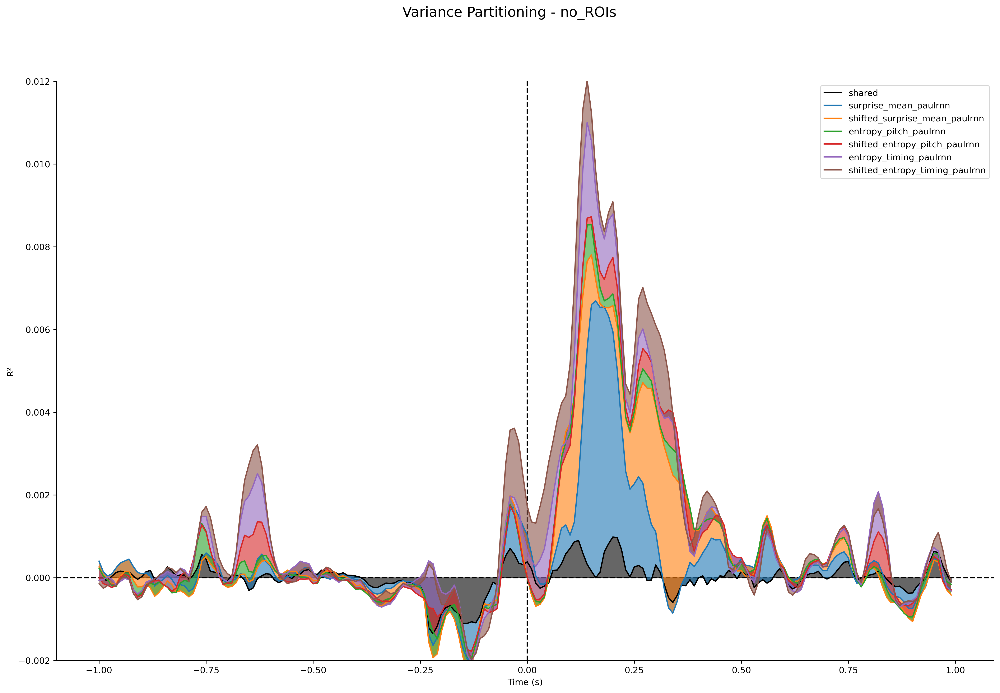

<Figure size 640x480 with 0 Axes>

In [67]:
from maestro_analysis.utils import fixed_golden_aspect_ratio
import random

ROI = None # None, ROI_idx_auditory_sub, ROI_idx_frontal_sub <-- for Desikan altas
ROI_name = 'no_ROIs' # 'no_ROIs', 'Auditory_ROIs', 'Frontal_ROIs' <-- for Desikan altas

#select time window
tw = [-1, 1.01]
times = reg_paulrnn[list(reg_acoustic.keys())[0]]['times']
lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
times = times[lim[0]:lim[1]]

#retrieve results from full model
data = {}
y = []
for isub, sub in enumerate(reg_acoustic.keys()):
    s = reg_paulrnn[sub]['subject_r2'] - reg_acoustic[sub]['subject_r2']
    s = s[:,lim[0]:lim[1]]
    if ROI is not None:
        mask = [idx for idx in ch_sign_sub[isub] if idx in ROI[isub]]
    else:
        mask = ch_sign_sub[isub]
    y.append(s[mask,:])
y = np.concatenate(y,axis=0)  
y = np.mean(y, axis = 0)
data['all'] = y

#retrieve results for each unique feature
for i, feat in enumerate(vp_feature):
    y = []
    for isub, sub in enumerate(reg_acoustic.keys()):
        s = vp_data[feat][sub]['subject_r2'] - reg_acoustic[sub]['subject_r2']
        s = s[:,lim[0]:lim[1]]
        if ROI is not None:
            mask = [idx for idx in ch_sign_sub[isub] if idx in ROI[isub]]
        else:
            mask = ch_sign_sub[isub]
        y.append(s[mask,:])
    y = np.concatenate(y,axis=0)  
    y = np.mean(y, axis = 0)
    data[feat] = data['all'] - y

#retrieve shared variance
data['shared'] = data['all'] - sum([data[feat] for feat in vp_feature])

# #manage colors
# colormap = plt.cm.gnuplot #nipy_spectral, Set1,Paired,gist_ncar
# n_lines = 0
# for sub in reg_acoustic.keys():
#     # n_lines += reg_paulrnn[sub]['subject_betas'].shape[1]
#     n_lines += reg_mperfrnn[sub]['subject_betas'].shape[1]
# colors = [colormap(i) for i in np.linspace(0, 1,n_lines)]
# random.shuffle(colors)

#fig
suptitle = 'Variance Partitioning - ' + ROI_name
fig, axs = plt.subplots(figsize=(20, 12), dpi=300)
fig.suptitle(suptitle, fontsize=16)
y = data['shared']
axs.plot(times,y, color = 'black', label = 'shared')
axs.fill_between(times, 0, y,alpha=0.6, color = 'black')
axs.set_xlabel('Time (s)')
axs.set_ylabel('R²')
axs.axvline(0, linestyle='--', color='k', zorder=0)
axs.axhline(0, linestyle='--', color='k', zorder=0)
# axs.set_title(feat)
axs.set_ylim([-0.002, 0.012])

for i, feat in enumerate(vp_feature):
    previous = copy.copy(y)
    y += data[feat]
    axs.plot(times,y, label = feat)
    axs.fill_between(times, previous, y,alpha=0.6)


fixed_golden_aspect_ratio(axs)
plt.legend()
plt.show()

plt.savefig(save_path + 'seeg_vp_'+ROI_name+'_paulrnn.svg')
plt.savefig(save_path + 'seeg_vp_'+ROI_name+'_paulrnn.png')

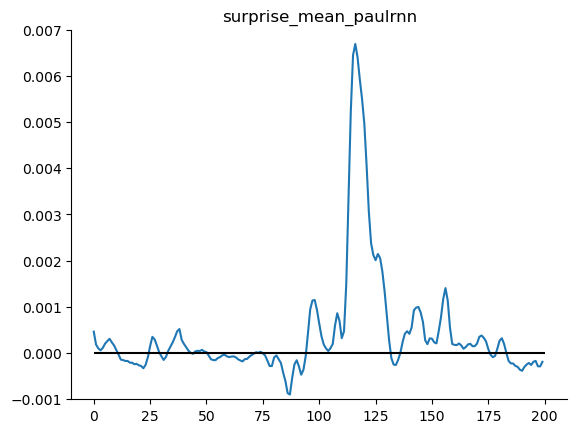

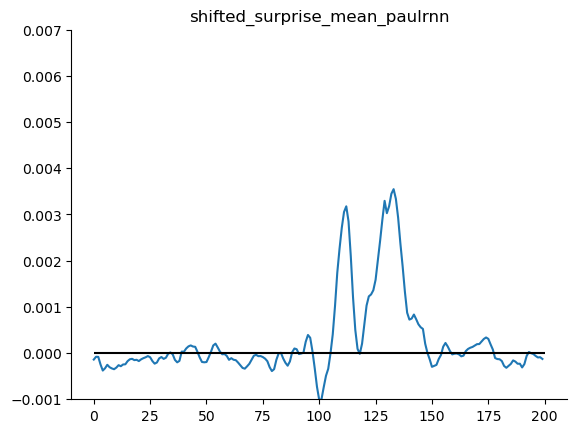

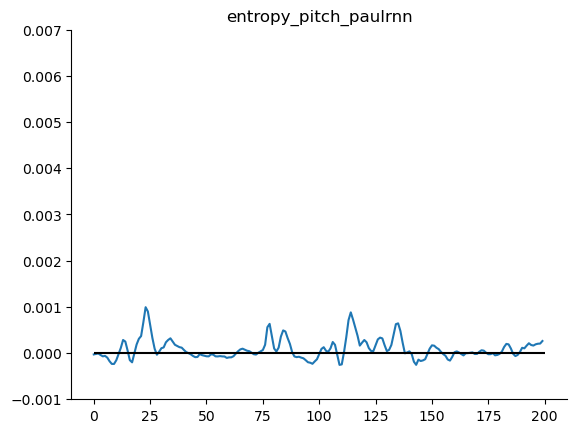

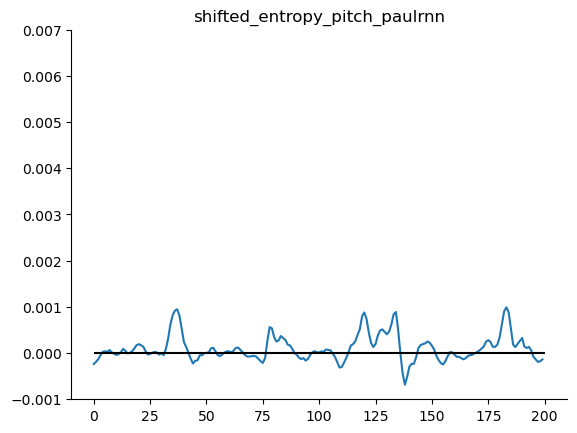

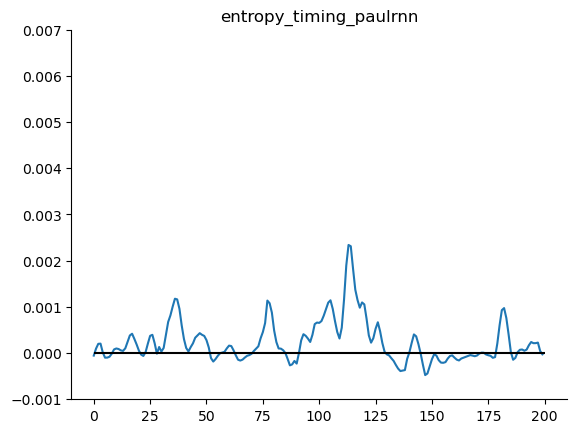

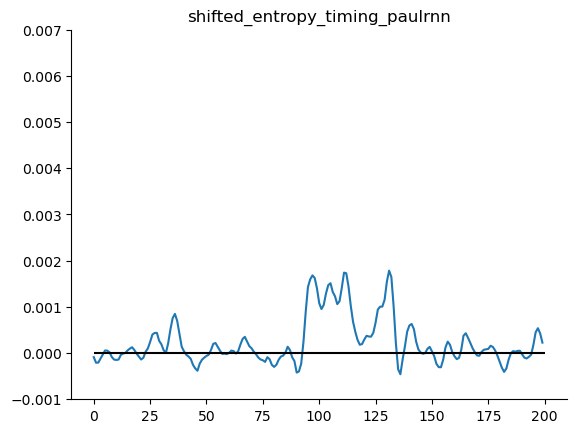

In [48]:
%matplotlib inline
for i, feat in enumerate(vp_feature):
    plt.plot(data[feat])
    plt.hlines(0,0,200,'k')
    plt.title(feat)
    plt.ylim([-0.001,0.007])
    plt.show()

# Plots on 3D brain

## Plot R² scores on 3D brain

In [19]:
from maestro_analysis.utils import plot_seeg

epochs_path = path + 'epochs_note_level/'
tw = [-1, 1]  #max [-1, 1]
cluster_thresh = 0.001
model = 'acoustic' #'paulrnn', 'mperfrnn', 'acoustic'

file_name = 'sign_Peak-R²_[' + str(tw[0]) + ',' + str(tw[1]) + ']_'+ model
scoring = u'ΔR²'
if model == 'acoustic':
  vlim = [0,0.15]
  s_thresh = 0.001
  title = 'Peak r² in tw [' + str(tw[0]) + ', ' + str(tw[1]) + '] || model : acoustic only || ' + 'n=10 || min peak-r² = ' + str(s_thresh)
else:
  vlim = [0,0.05]
  s_thresh = cluster_thresh
  title = 'Peak r² in tw [' + str(tw[0]) + ', ' + str(tw[1]) + '] || model : '+ model + ' || All - acoustic || ' + 'n=10 || min r² = ' + str(s_thresh)

scores = []
mask = []
i_ch = 0
for sub in reg_acoustic:
  if model == 'paulrnn':
    s = reg_paulrnn[sub]['subject_r2'] - reg_acoustic[sub]['subject_r2'] #r2
  elif model == 'mperfrnn':
    s = reg_mperfrnn[sub]['subject_r2'] - reg_acoustic[sub]['subject_r2'] #r2
  elif model == 'acoustic':
    s = reg_acoustic[sub]['subject_r2']

  lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
  s = s[:,lim[0]:lim[1]]
  s = np.max(s, axis=1)

  if model != 'acoustic':
    for _ in range(s.shape[0]):
      if i_ch not in ch_sign:
        s[_] = np.nan
      i_ch+=1
  
  scores.append(s)
  mask.append(s>s_thresh)

montages = [reg_acoustic[sub]['montage'] for sub in reg_acoustic]

fig = plot_seeg(scores, scoring, mask, vlim, montages, title, fs_path, save_path + file_name + '_.png', epochs_path, colormap = 'custom');

Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 148
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
5437 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 170
Reading D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 137
Reading D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10764 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 177
Reading D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 182
Reading D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
8671 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 159
Reading D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 168
Reading D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 158
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 166
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 180


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:680: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


## Model difference

In [15]:
#distribution across channels
diff_measure = 'mean' #mean or max

tw = [-1, 1]
scores = []
i_ch = 0
for sub in reg_acoustic:
  s = reg_paulrnn[sub]['subject_r2'] - reg_mperfrnn[sub]['subject_r2']

  lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
  s = s[:,lim[0]:lim[1]]

  if diff_measure == 'mean':
    s = np.mean(s, axis=1)
  elif diff_measure == 'max':
    idx_max = np.argmax(np.abs(s),axis=1)
    s = np.array([s[i,t] for i,t in enumerate(idx_max)])
  
  scores.append(s)

scores = np.concatenate(scores,axis=0)

fig, ax = plt.subplots()
ax.hist(scores,bins=100)
if diff_measure == 'mean':
  ax.set_xlim([-0.0004,0.0004])
elif diff_measure == 'max':
  ax.set_xlim([-0.01,0.01])
ax.vlines(0,ax.get_ylim()[0],ax.get_ylim()[1], linestyles='--', colors='black')

if diff_measure == 'mean':
  ax.ticklabel_format(axis='x',style='sci',scilimits=(0,0))
# ax.set_xlabel(r'$R²_{PaulRNN} - R²_{PerfRNN}$')
ax.set_xlabel(r'$R²_{Custom RNN} - R²_{PerfRNN}$')
ax.set_ylabel('Channel count')
ax.set_title('Distribution of model difference across channels')
ax.text(2e-4,150,'***', fontsize=16)

plt.savefig(save_path+'model_difference_distribution_'+diff_measure+'.png',dpi=300)
plt.show()

stat = scipy.stats.ttest_1samp(scores, 0, axis=0, nan_policy='propagate', alternative='two-sided')
print('T = ', stat.statistic, 'p = ', stat.pvalue)

T =  7.873906603684109 p =  6.183661224842234e-15


C:\Users\paull\AppData\Local\Temp\ipykernel_10776\1346195314.py:40: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


In [16]:
#average across channels

tw = [-1, 1]
scores = []
i_ch = 0
for sub in reg_acoustic:
  s = reg_paulrnn[sub]['subject_r2'] - reg_mperfrnn[sub]['subject_r2']
  lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
  s = s[:,lim[0]:lim[1]]
  scores.append(s)

scores = np.concatenate(scores,axis=0)
scores_m = np.mean(scores,axis=0)
scores_sem = np.std(scores,axis=0) / np.sqrt(scores.shape[0])

fig, ax = plt.subplots()
ax.plot(times[:-1],scores_m, label='Model difference', color = 'black')
ax.fill_between(times[:-1], scores_m-scores_sem, scores_m+scores_sem,alpha=0.6, color = 'grey')
ax.set_ylim([-0.0005,0.0005])

ax.axvline(0, linestyle='--', color='k', zorder=0)
ax.axhline(0, linestyle='--', color='k', zorder=0)

ax.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
ax.set_xlabel('Time (sec)')
ax.set_ylabel(r'$R²_{PaulRNN} - R²_{PerfRNN}$')
ax.set_title('Average model difference')

plt.savefig(save_path+'model_difference_time_'+diff_measure+'.png',dpi=300)
plt.show()

stat = scipy.stats.ttest_1samp(scores_m, 0, axis=0, nan_policy='propagate', alternative='two-sided')
print('T = ', stat.statistic, 'p = ', stat.pvalue)

T =  6.9371062841890625 p =  5.5545114618559466e-11


C:\Users\paull\AppData\Local\Temp\ipykernel_10776\1396091638.py:30: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


In [17]:
from maestro_analysis.utils import plot_seeg

epochs_path = path + 'epochs_note_level/'
tw = [-1, 1]  #max [-1, 1]
model = 'paulrnn'

if diff_measure == 'max':
  file_name = 'model_difference_peak-R²_[' + str(tw[0]) + ',' + str(tw[1]) + ']_'+model
  vlim = [-0.01,0.01]
  s_thresh = 0.002
elif diff_measure == 'mean':
  file_name = 'model_difference_mean-R²_[' + str(tw[0]) + ',' + str(tw[1]) + ']_'+model
  vlim = [-0.001,0.001]
  s_thresh = 0.0002
scoring = u'ΔR²'
title = 'Model difference (paul - mperf) in tw [' + str(tw[0]) + ', ' + str(tw[1]) + '] || n=10 || measure: ' + diff_measure + ' || min_diff = ' + str(s_thresh)

scores = []
mask = []
i_ch = 0
for sub in reg_acoustic:
  s = reg_paulrnn[sub]['subject_r2'] - reg_mperfrnn[sub]['subject_r2']

  lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
  s = s[:,lim[0]:lim[1]]
  if diff_measure == 'mean':
    s = np.mean(s, axis=1)
  elif diff_measure == 'max':
    idx_max = np.argmax(np.abs(s),axis=1)
    s = np.array([s[i,t] for i,t in enumerate(idx_max)])
  
  scores.append(s)
  # mask.append(np.full(s.shape,True))
  mask.append(np.abs(s)>s_thresh)

montages = [reg_acoustic[sub]['montage'] for sub in reg_acoustic]

fig = plot_seeg(scores, scoring, mask, vlim, montages, title, fs_path, save_path + file_name + '.png', epochs_path, colormap = 'diverging')

Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 148
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif ...
    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


5437 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 170
Reading D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 137
Reading D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10764 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 177
Reading D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 182
Reading D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
8671 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 159
Reading D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 168
Reading D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 158
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 166
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 180


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:680: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


## Plot timings on 3D brain

In [ ]:
from maestro_analysis.utils import plot_seeg

epochs_path = path + 'epochs_note_level/'
tw = [-1, 1]
s_thresh = 0.003
file_name = 'Peak-R²-timing'
scoring = 'Time (sec)'
title = 'Timing of Peak r² in tw [' + str(tw[0]) + ', ' + str(tw[1]) + '] || model : '+ model + ' || All - acoustic || ' + 'n=10 || min r² = ' + str(s_thresh)

timings = []
mask = []
for sub in reg_acoustic:
  s = reg_paulrnn[sub]['subject_r2'] - reg_acoustic[sub]['subject_r2'] #r2

  lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
  t = times[np.argmax(s, axis=1)]
  s = s[:,lim[0]:lim[1]]
  s = np.max(s, axis=1)

  mask.append(s>s_thresh)
  timings.append(t)

montages = [reg_acoustic[sub]['montage'] for sub in reg_acoustic]

fig = plot_seeg(timings, scoring, mask, tw, montages, title, fs_path, save_path + file_name + '.png', epochs_path, colormap = 'diverging')

## Plot Betas on 3D brain

In [35]:
from maestro_analysis.utils import plot_seeg

epochs_path = path + 'epochs_note_level/'
tw = [-1.0, 1.0]  #max [-1, 1]
b_thresh = 0.02
vlim = [0,0.2]
scoring = 'a.u.'
plot_timing = True


feature_name = ['surprise_mean_paulrnn', 'entropy_pitch_paulrnn'] #['surprise', 'uncertainty', 'psum']
feature_idx = [15,16]

for iF, f_name in enumerate(feature_name):
    f_idx = features.index(f_name)

    file_name_peak = 'Peak-beta_' + feature_name[iF] + '_[' + str(tw[0]) + ',' + str(tw[1]) + ']'
    file_name_timing = 'Peak-beta_' + feature_name[iF] + '_timing'
    title = 'Peak-beta_' + feature_name[iF] + ' in tw [' + str(tw[0]) + ', ' + str(tw[1]) + '] || model : '+ model + ' || All - acoustic || ' + 'n=10 || min r² = ' + str(b_thresh)

    betas = []
    timings = []
    mask = []
    for sub in reg_acoustic:
        b = reg_paulrnn[sub]['subject_betas'][f_idx,:,:]
        b = np.abs(b)

        lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
        b = b[:,lim[0]:lim[1]]
        t = times[lim[0] + np.argmax(b, axis=1)]
        b = np.max(b, axis=1)
        
        betas.append(b)
        mask.append(b>b_thresh)
        timings.append(t)

    montages = [reg_acoustic[sub]['montage'] for sub in reg_acoustic]

    fig = plot_seeg(betas, scoring, mask, vlim, montages, title, fs_path, save_path + file_name_peak + '.png', epochs_path, colormap = 'custom')
    if plot_timing == True:
        fig = plot_seeg(timings, 'Time (sec)', mask, [-1,1], montages, title, fs_path, save_path + file_name_timing + '.png', epochs_path, colormap = 'diverging')

Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 148
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
5437 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 170
Reading D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 137
Reading D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10764 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 177
Reading D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 182
Reading D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
8671 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 159
Reading D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 168
Reading D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 158
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 166
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 180
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:680: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()
C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 148
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
5437 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 170
Reading D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 137
Reading D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10764 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 177
Reading D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 182
Reading D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
8671 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 159
Reading D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 168
Reading D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 158
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 166
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 180
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:680: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()
C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 148
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
5437 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 170
Reading D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 137
Reading D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10764 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 177
Reading D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 182
Reading D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
8671 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 159
Reading D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 168
Reading D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 158
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 166
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 180
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:680: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()
C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 148
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
5437 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 170
Reading D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 137
Reading D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10764 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 177
Reading D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 182
Reading D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
8671 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 159
Reading D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 168
Reading D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 158
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 166
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 180


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:680: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


## Plot NMF/PCA components on 3D brain

Removed:  Dav_To


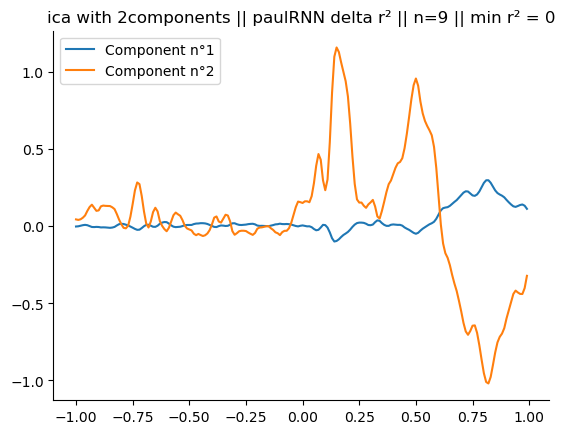

In [8]:
from maestro_analysis.utils import plot_seeg

method = 'ica' #nmf or ica
epochs_path = path + 'epochs_note_level/'
tw = [-1, 1]  #max [-1, 1]
n_components = 2
s_thresh = 0
vlim = None

times = reg_paulrnn[list(reg_acoustic.keys())[0]]['times']
lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
times = times[lim[0]:lim[1]]

# load scores
scores = []
n_chan = []
for sub in reg_acoustic:
  if sub == 'Dav_To':
    print('Removed: ', sub)
    continue

  s = reg_paulrnn[sub]['subject_r2'] - reg_acoustic[sub]['subject_r2'] #r2
  s = s[:,lim[0]:lim[1]]
  scores.append(s)
  n_chan.append(s.shape[0])
scores = np.concatenate(scores, axis=0)
scores = np.where(scores>s_thresh,scores,0)

# # compute decomposition 
if method == 'nmf':
  nmf = NMF(n_components=n_components, init=None)
  W = nmf.fit_transform(scores) #shape: n_channels, n_components
  H = nmf.components_  #shape: n_components, n_timepoints

  # n_rep = 1000 #(n_times, and then average, to handle the effect of random initialization)
  # W = []
  # H = []
  # for i in range(n_rep):
  #   nmf = NMF(n_components=n_components, init='random', random_state=i) #None, random or nndsvdar
  #   W.append(nmf.fit_transform(scores)) #shape: n_channels, n_components
  #   H.append(nmf.components_)  #shape: n_components, n_timepoints
  # W = np.mean(np.array(W), axis = 0)
  # H = np.mean(np.array(H), axis = 0)
elif method == 'ica':
    n_rep = 1000 #(n_times, and then average, to handle the effect of random initialization)
    W = []
    H = []
    for i in range(n_rep):
      ica = FastICA(n_components=n_components, w_init=None, whiten='unit-variance', random_state=i)
      W.append(ica.fit_transform(scores)) #shape: n_channels, n_components
      H.append(ica.components_)  #shape: n_components, n_timepoints
    W = np.mean(np.array(W), axis = 0)
    H = np.mean(np.array(H), axis = 0)


if method == 'nmf':
  #R²
  base = np.sum((scores - np.mean(scores))**2)
  ss = np.sum((scores - (W@H))**2)
  r2 = 1 - (ss/base)
  print('R²', r2)

#plot dynamic of components
%matplotlib inline
for i in range(n_components):
  plt.plot(times,H[i,:], label = 'Component n°' + str(i+1))
plt.legend()
plt.title(method +' with ' + str(n_components) + 'components || paulRNN delta r² || n=9 || min r² = ' + str(s_thresh))
plt.savefig(save_path + method + '/'+method+'_temporal_comps.png')
plt.show()

Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 148
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif ...
    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
5437 matching events found
No baseline correction applied
0 projection items activated


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


Channel types::	seeg: 170
Reading D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 137
Reading D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
10764 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 177
Reading D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 182
Reading D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif ...
    Found the data of interest:


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
8671 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 159
Reading D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 168
Reading D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 158
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 166


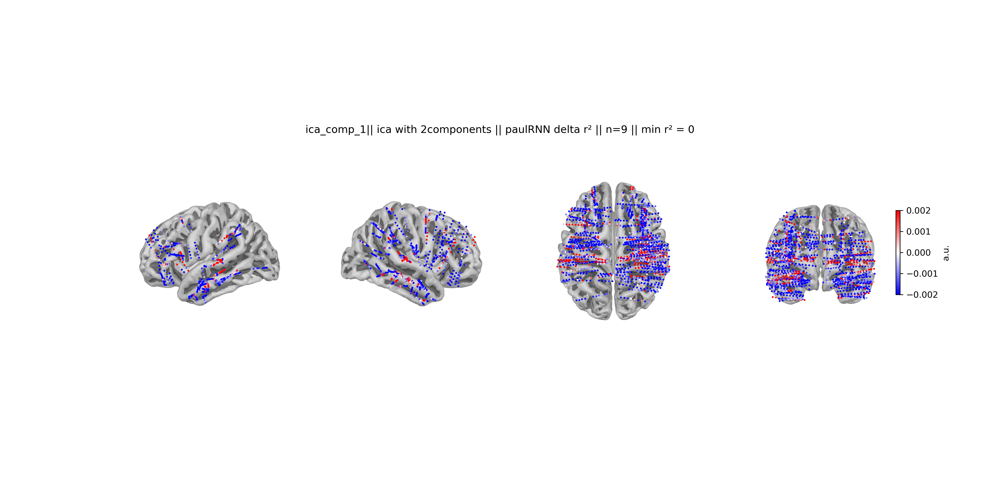

Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 148
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif ...
    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
5437 matching events found
No baseline correction applied
0 projection items activated


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


Channel types::	seeg: 170
Reading D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 137
Reading D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
10764 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 177
Reading D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 182
Reading D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif ...
    Found the data of interest:


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
8671 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 159
Reading D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 168
Reading D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 158
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 23 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 166


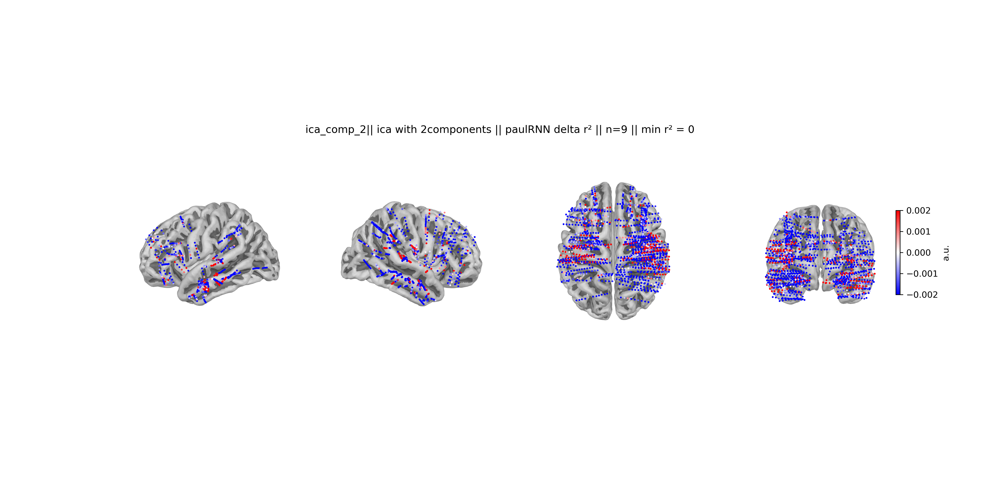

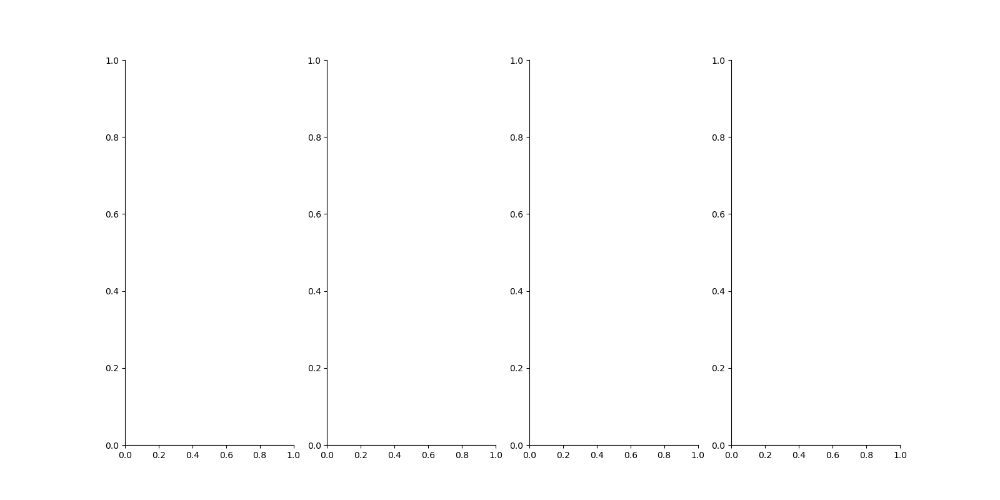

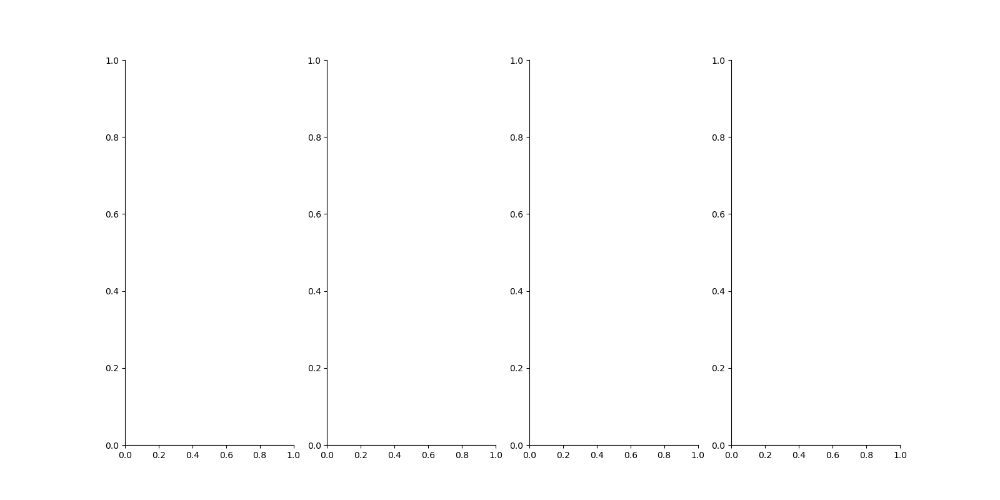

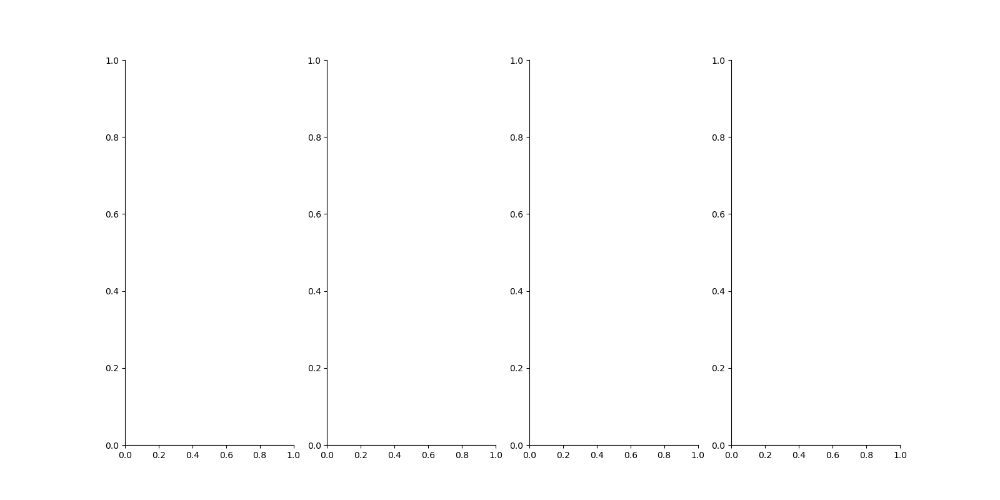

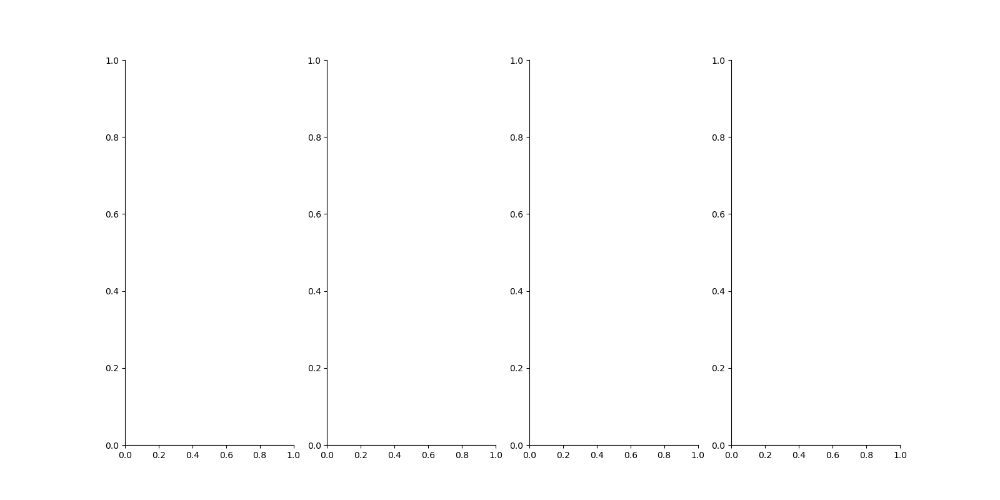

...

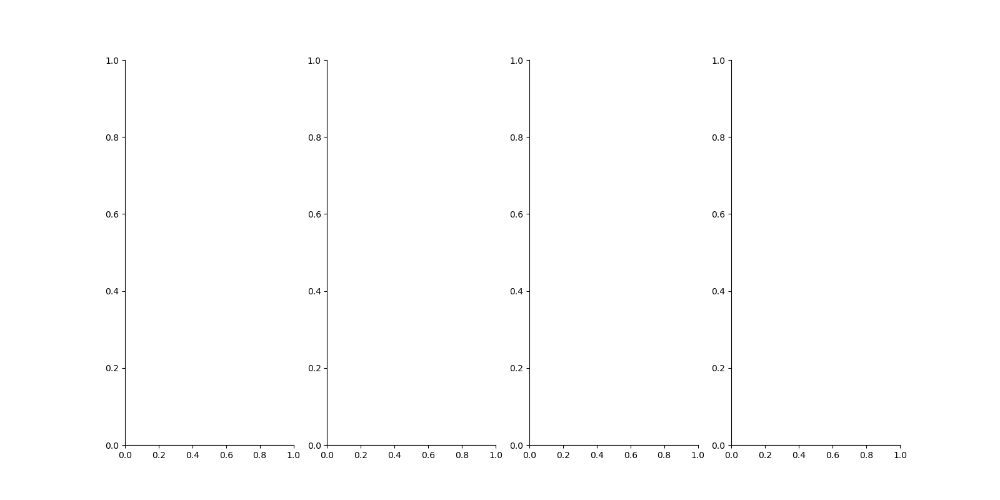

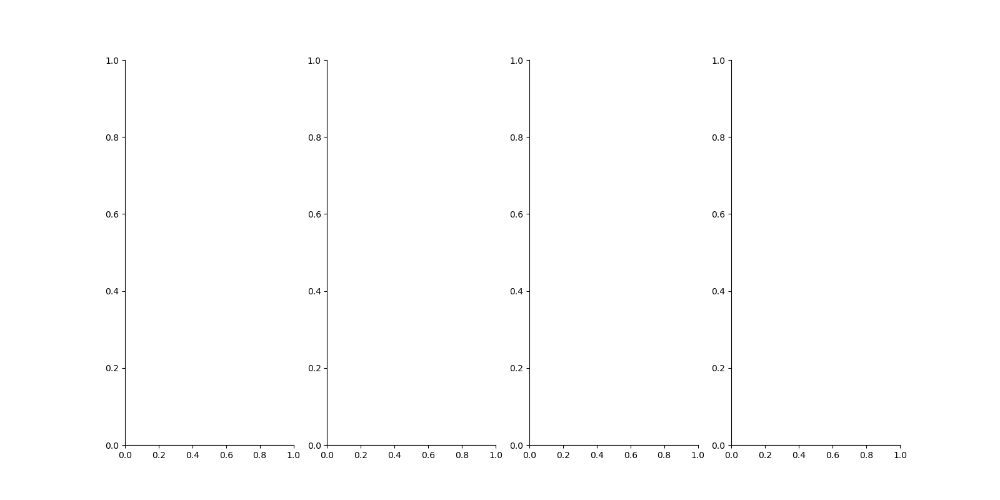

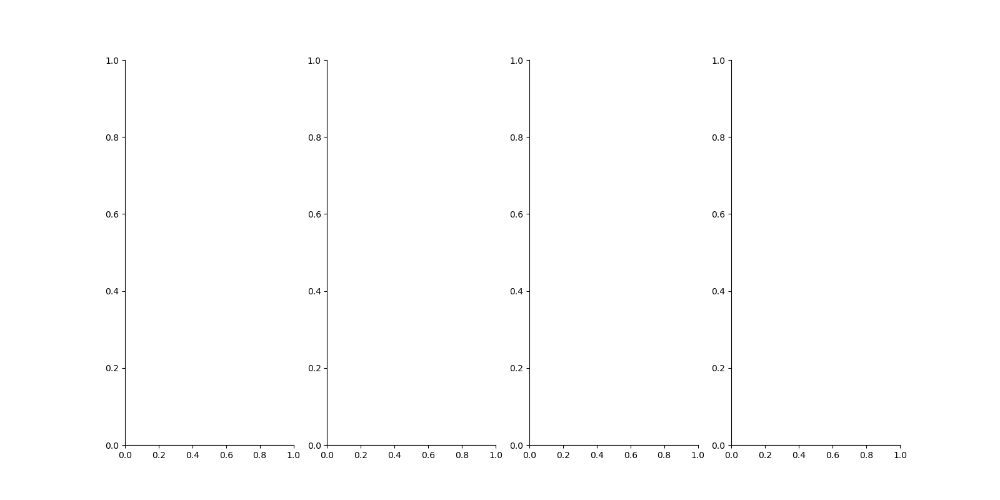

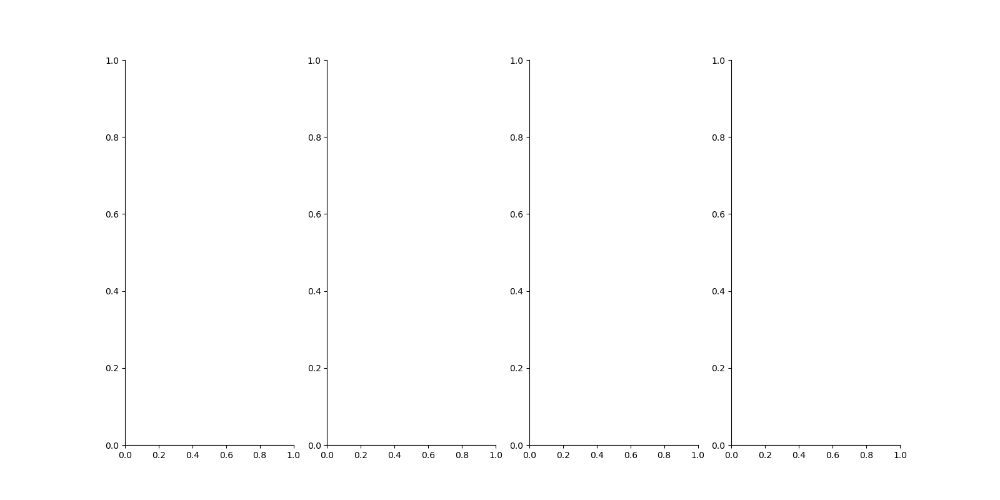

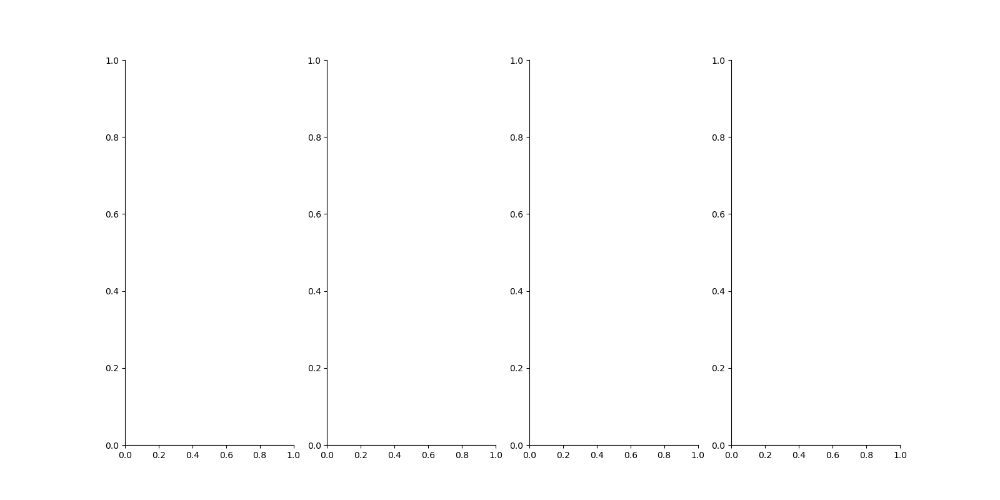

In [14]:
# plot components on 3D brain
if method =='ica':
    vlim = [-0.002,0.002]
    colormap = 'diverging'
elif method == 'nmf':
    vlim = [0.001,0.02] #[0,np.max(W)]
    colormap = 'custom'
mask = None
montages = [reg_acoustic[sub]['montage'] for sub in reg_acoustic if sub != 'Dav_To']
%matplotlib ipympl
for i in range(n_components):
    file_name = method+'_spatial_comp_'+str(i+1)
    scoring = 'a.u.'
    title = method+'_comp_'+str(i+1) + '|| '+method+' with ' + str(n_components) + 'components || paulRNN delta r² || n=9 || min r² = ' + str(s_thresh)

    #re attribute channels to each subjects, so that it doesn't mess up with montage infos
    comp = []
    mask = []
    idx = 0
    for isub in range(len(n_chan)):
        comp.append(W[idx:idx+n_chan[isub],i])
        mask.append(np.full((n_chan[isub],), True))
        idx += n_chan[isub]
    fig = plot_seeg(comp, scoring, mask, vlim, montages, title, fs_path, save_path + method +'/' + file_name + '.png', epochs_path, colormap = colormap)

# Visualisation test

Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_15540\1420813958.py:39: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 148
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_15540\1420813958.py:39: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
5437 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 170
Reading D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_15540\1420813958.py:39: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 137
Reading D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_15540\1420813958.py:39: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10764 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 177
Reading D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_15540\1420813958.py:39: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 182
Reading D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_15540\1420813958.py:39: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
8671 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 159
Reading D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_15540\1420813958.py:39: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 168
Reading D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_15540\1420813958.py:39: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 158
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_15540\1420813958.py:39: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 166
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_15540\1420813958.py:39: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 180
1 (2, 2)
2 (2, 2)


C:\Users\paull\AppData\Local\Temp\ipykernel_15540\1420813958.py:152: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


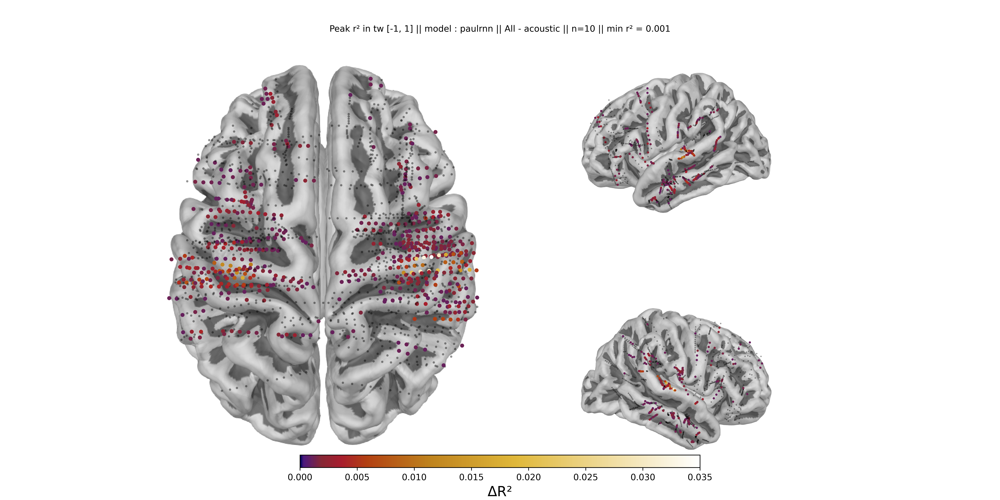

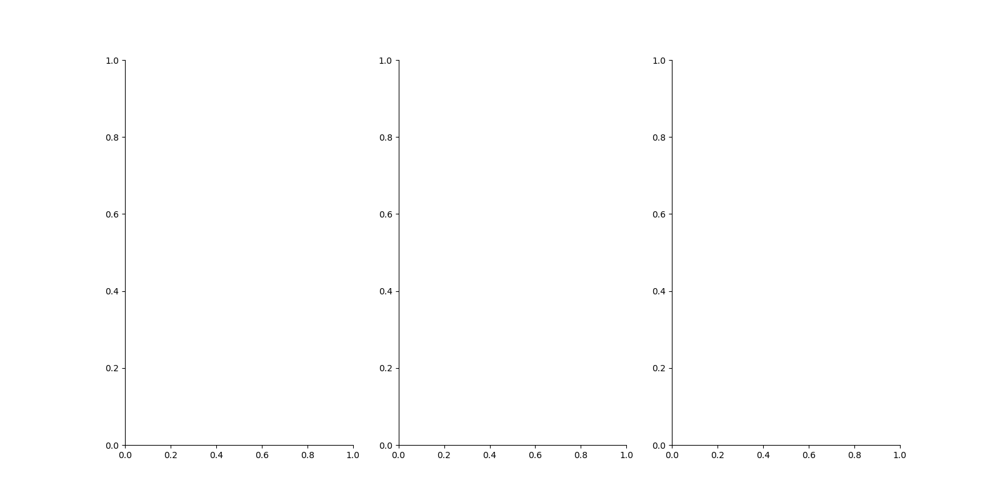

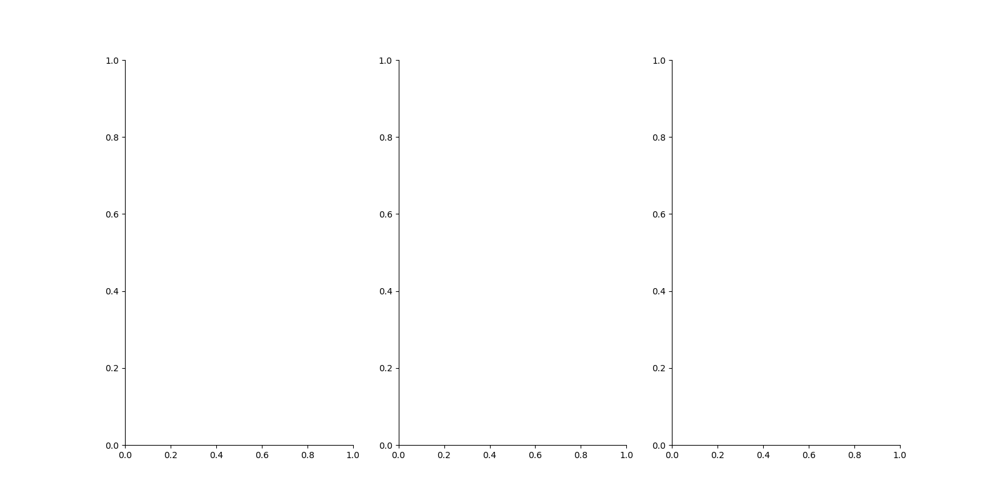

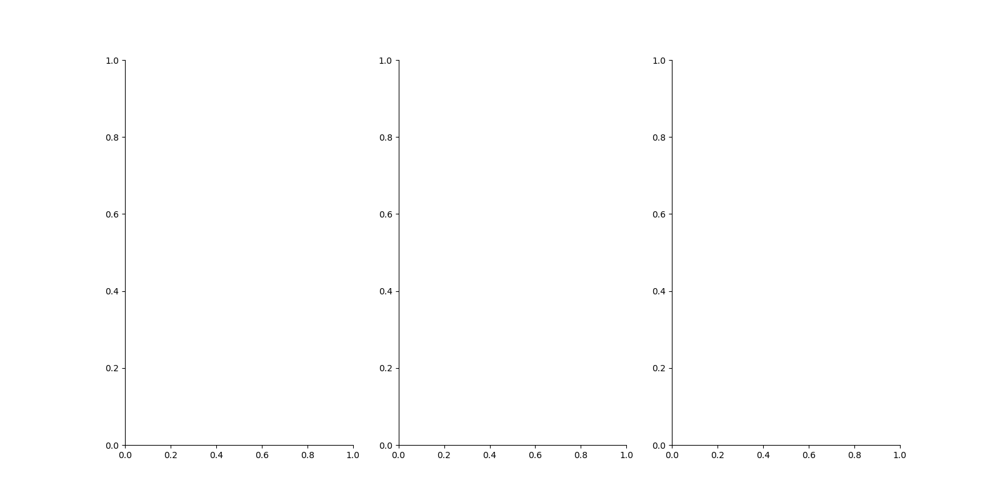

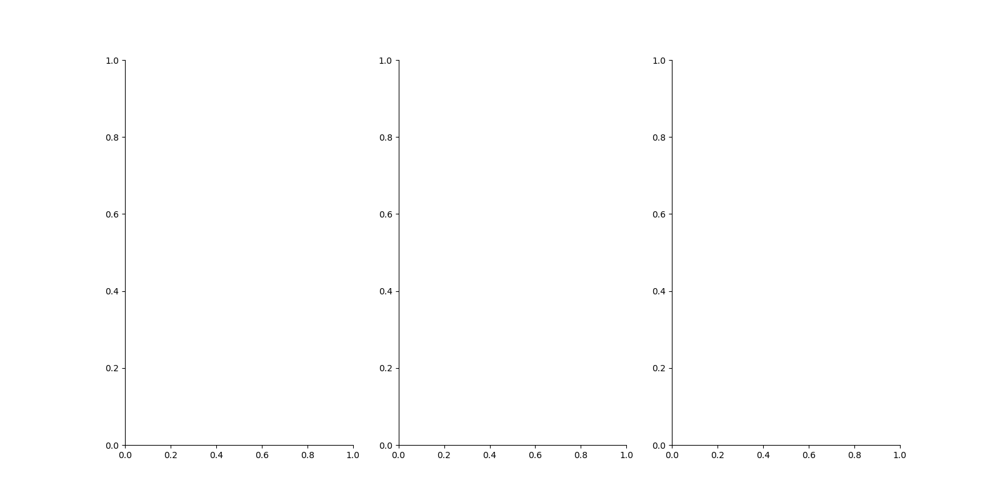

...

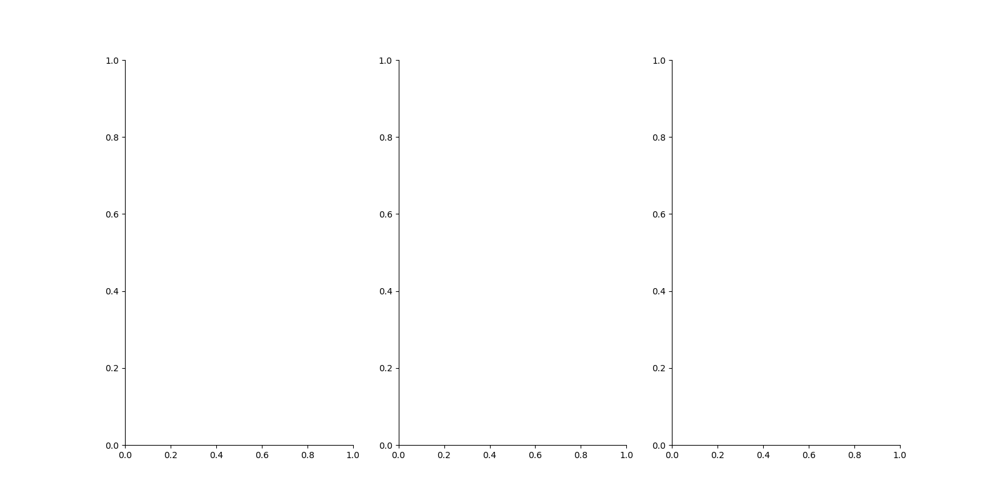

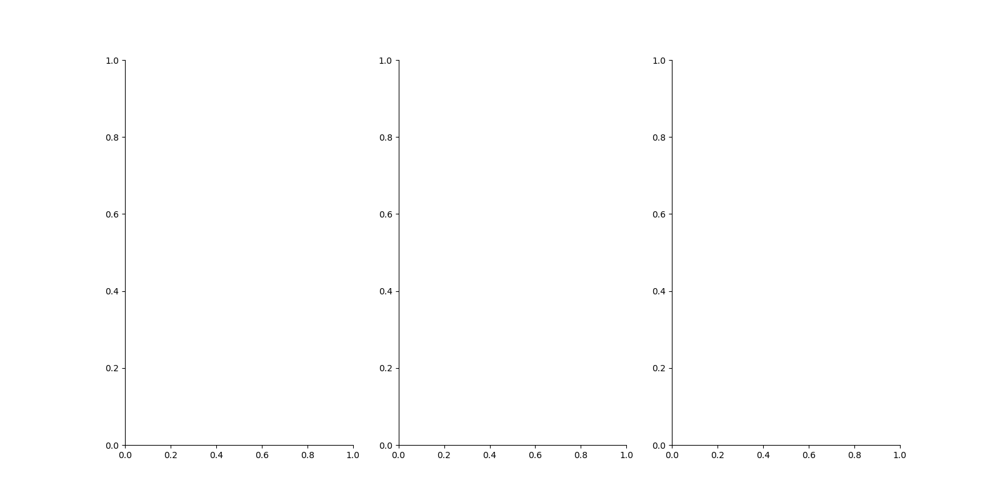

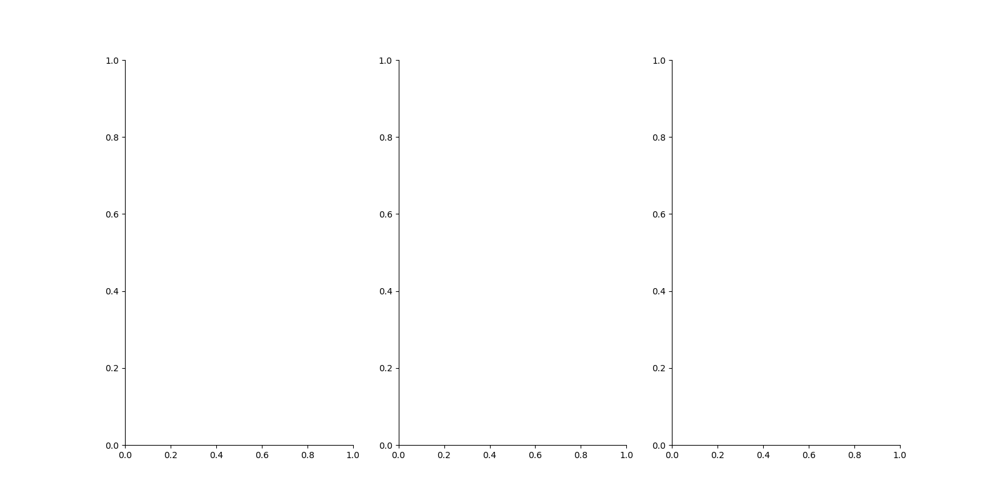

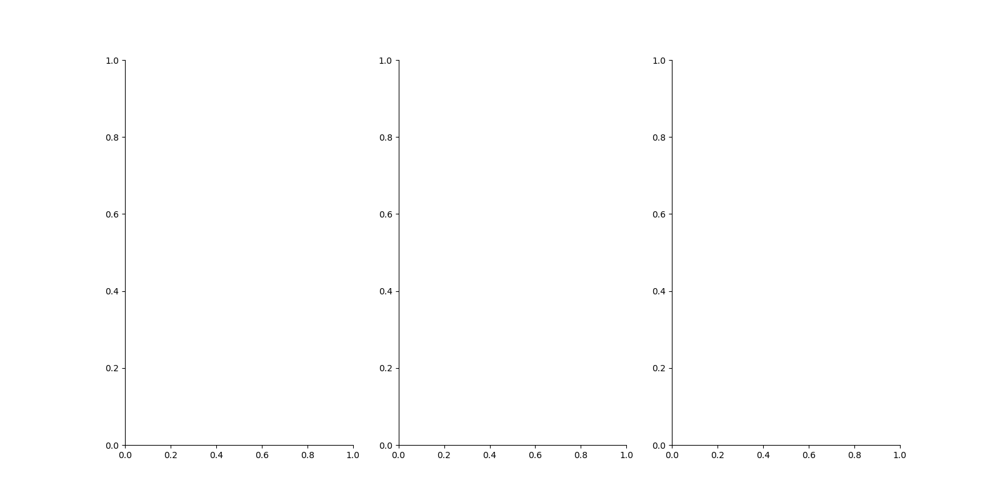

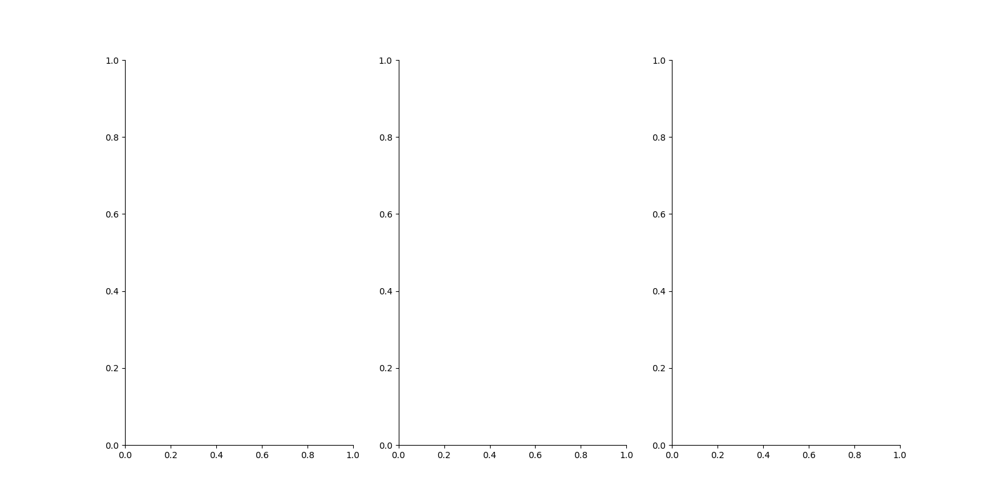

In [112]:
from maestro_analysis.utils import plot_seeg

model = 'paulrnn'
epochs_path = path + 'epochs_note_level/'
tw = [-1, 1]  #max [-1, 1]

file_name = '___Peak-R²_[' + str(tw[0]) + ',' + str(tw[1]) + ']_'+ model
scoring = u'ΔR²'
vlim = [0,0.035]
s_thresh = 0.001
title = 'Peak r² in tw [' + str(tw[0]) + ', ' + str(tw[1]) + '] || model : '+ model + ' || All - acoustic || ' + 'n=10 || min r² = ' + str(s_thresh)

scores = []
mask = []
for sub in reg_acoustic:
  s = reg_paulrnn[sub]['subject_r2'] - reg_acoustic[sub]['subject_r2']
  lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
  s = s[:,lim[0]:lim[1]]
  s = np.max(s, axis=1)
  
  scores.append(s)
  mask.append(s>s_thresh)

montages = [reg_acoustic[sub]['montage'] for sub in reg_acoustic]

fig = plot_seeg_gridspec(scores, scoring, mask, vlim, montages, title, fs_path, save_path + file_name + '_.png', epochs_path, colormap = 'custom');

[[<AxesSubplot:> <AxesSubplot:>]
 [<AxesSubplot:> <AxesSubplot:>]]


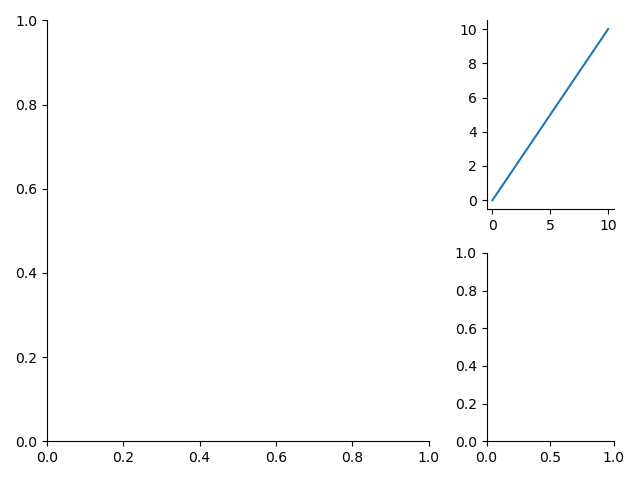

In [48]:
%matplotlib ipympl
# plt.switch_backend('TkAgg')
fig, axs = plt.subplots(2, 2, gridspec_kw={'width_ratios': [3, 1]})
gs = axs[0, 0].get_gridspec()
# remove the underlying axes
for ax in axs[:, 0]:
    ax.remove()
axbig = fig.add_subplot(gs[:, 0])
print(axs)
axs[0,1].plot(np.linspace(0,10), np.linspace(0,10))
fig.tight_layout()
plt.show()

## sEEG coverage

In [18]:
fs_path

'D:/2022_deep_music/seeg/freesurfer/'

In [19]:
subj = list(reg_paulrnn.keys())
sub_idx_list = [ i for i in range(len(subj))]

#azimuth, elevation, roll, distance
aerd = [[180,90,0,0.4],
        [0,90,0,0.4],
        [180,0,0,0.4],
        [90,90,0,0.4]] 
xy_list = [[] for i in range(len(aerd))]
for sub_idx in sub_idx_list:
  print('Retrieving montage for : ', subj[sub_idx])
  preprocessed_data = path + "epochs_note_level/" + subj[sub_idx] + "_epochs_mono_preprocessed_IDA.fif"

  #load original data
  epochs = mne.read_epochs(preprocessed_data,preload=False)

  # get montage for whole brain and each hemisphere
  montage = reg_acoustic[subj[sub_idx]]['montage']
  ch_L, ch_R = [], []
  dig_L, dig_R = [], []
  for i_ch, ch in enumerate(montage.ch_names):
    if "'" in ch:
      ch_L.append(ch)
      dig_L.append(montage.dig[i_ch])
    else:
      ch_R.append(ch)
      dig_R.append(montage.dig[i_ch])
  montage_L = mne.channels.DigMontage(dig=dig_L, ch_names=ch_L)
  montage_R = mne.channels.DigMontage(dig=dig_R, ch_names=ch_R)
  
  head_fs = mne.transforms.Transform('head', 'mri',trans=None)
  fig = mne.viz.plot_alignment(epochs.info, trans=head_fs, subject= 'fsaverage', coord_frame = 'mri',
                        subjects_dir=fs_path, surfaces=dict(pial=0.95))
  fig.plotter.set_background(color=[1.0, 1.0, 1.0])

  fig2, axes = plt.subplots(1,len(aerd),figsize=(16, 8))
  for i_pos in range(len(aerd)):
    mne.viz.set_3d_view(figure=fig, azimuth=aerd[i_pos][0], elevation=aerd[i_pos][1],roll=aerd[i_pos][2],distance=aerd[i_pos][3])
    if i_pos == 0:
      M = montage_L
    elif i_pos == 1:
      M = montage_R
    else:
      M = montage
    xy, im = mne.viz.snapshot_brain_montage(fig, M,hide_sensors=True)
    # Convert from a dictionary to array to plot
    xy_pts = np.vstack([xy[ch] for ch in M.ch_names])
    xy_list[i_pos].append(xy_pts.T)
  fig.plotter.close()

color = plt.cm.CMRmap(np.linspace(0, 1, len(subj)))   #https://matplotlib.org/stable/gallery/color/colormap_reference.html
brain = mne.viz.Brain(subjects_dir=fs_path, subject_id = 'fsaverage',
                      surf='pial', #'pial', 'inflated', 'white',...
                      background='white',
                      alpha = 0.95,
                      cortex='classic',
                      offscreen=True)

# brain.add_annotation('HCPMMP1_combined') #'HCPMMP1', 'HCPMMP1_combined', 'aparc_sub'

fig, axes = plt.subplots(1,len(aerd),figsize=(16, 8))
for i_pos in range(len(aerd)):
  brain.show_view(azimuth=aerd[i_pos][0], elevation=aerd[i_pos][1],roll=aerd[i_pos][2],distance=aerd[i_pos][3]*1000)
  im = brain.screenshot()

  # This allows us to use matplotlib to create arbitrary 2d scatterplots
  axes[i_pos].imshow(im)
  for i_sub in range(len(subj)):
    xy = xy_list[i_pos][i_sub]
    # scatt_1 = axes[i_pos].scatter(*xy, c='black', s=3, alpha=0.7,marker='o')
    scatt_2 = axes[i_pos].scatter(*xy, color=color[i_sub,:], s=2, alpha=1,marker='.', label = 'sub #' + str(i_sub))
  # cmap_contour = axes[i_pos].scatter(*xy_pts[np.where(scores>thresh)[0],:].T, edgecolors='black',facecolors='none', s=50, alpha=1,marker='o')
  axes[i_pos].set_axis_off()

axes[len(aerd)-1].legend(loc = 'center', bbox_to_anchor = (0.5,0), ncol = 2)
fig.suptitle('sEEG dataset coverage (n=' + str(len(subj)) + ')' ,y=0.75)
plt.show()
fig.savefig(path+'regression_note_level/sEEG_coverage.png')
brain.plotter.close()

Retrieving montage for :  Bou_Al
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_22696\3429554282.py:15: RuntimeWarning: This filename (D:/2022_deep_music/seeg/epochs_note_level/Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(preprocessed_data,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 148
Retrieving montage for :  Bou_Ni
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_22696\3429554282.py:15: RuntimeWarning: This filename (D:/2022_deep_music/seeg/epochs_note_level/Bou_Ni_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(preprocessed_data,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
5437 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 170
Retrieving montage for :  Dav_To
Reading D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_22696\3429554282.py:15: RuntimeWarning: This filename (D:/2022_deep_music/seeg/epochs_note_level/Dav_To_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(preprocessed_data,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 137


C:\Users\paull\AppData\Local\Temp\ipykernel_22696\3429554282.py:36: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig2, axes = plt.subplots(1,len(aerd),figsize=(16, 8))


Retrieving montage for :  Dri_Am
Reading D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_22696\3429554282.py:15: RuntimeWarning: This filename (D:/2022_deep_music/seeg/epochs_note_level/Dri_Am_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(preprocessed_data,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10764 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 177
Retrieving montage for :  Gra_Lu
Reading D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_22696\3429554282.py:15: RuntimeWarning: This filename (D:/2022_deep_music/seeg/epochs_note_level/Gra_Lu_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(preprocessed_data,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 182
Retrieving montage for :  Pen_Va
Reading D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_22696\3429554282.py:15: RuntimeWarning: This filename (D:/2022_deep_music/seeg/epochs_note_level/Pen_Va_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(preprocessed_data,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
8671 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 159
Retrieving montage for :  Sou_Fa
Reading D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_22696\3429554282.py:15: RuntimeWarning: This filename (D:/2022_deep_music/seeg/epochs_note_level/Sou_Fa_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(preprocessed_data,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 168
Retrieving montage for :  The_Mo
Reading D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_22696\3429554282.py:15: RuntimeWarning: This filename (D:/2022_deep_music/seeg/epochs_note_level/The_Mo_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(preprocessed_data,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 158
Retrieving montage for :  Tou_Et
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_22696\3429554282.py:15: RuntimeWarning: This filename (D:/2022_deep_music/seeg/epochs_note_level/Tou_Et_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(preprocessed_data,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 166
Retrieving montage for :  Tou_Ma
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_22696\3429554282.py:15: RuntimeWarning: This filename (D:/2022_deep_music/seeg/epochs_note_level/Tou_Ma_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(preprocessed_data,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 180


C:\Users\paull\AppData\Local\Temp\ipykernel_22696\3429554282.py:77: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


In [20]:
path+'regression_note_level/sEEG_coverage.png'

'D:/2022_deep_music/seeg/regression_note_level/sEEG_coverage.png'

In [55]:
import pathlib
def plot_seeg_coverage_gridspec(montages, fs_path, save_path, epochs_path):
  """
  scores: list of arrays (n_channels,)
  scoring: name of scoring to use on plot
  mask: binary matrix for channel selection
  vlim: limits of colorbar, [vmin, vmax]
  montages: list of montage
  title: title of fig 
  fs_path: path to fsaverage files
  save_path: path and name of .png output
  epochs_path: path to epochs folder. TO BE REMOVED
  colormap: 'custom' for darkblue to yellow, or 'diverging' for blue to red
  """

  # plt.switch_backend('TkAgg')

  #azimuth, elevation, roll, distance
  aerd = [[180,0,0,0.4],
          [180,90,0,0.4],
          [0,90,0,0.4]]
  xy_list = [[] for i in range(len(aerd))]

  # some parameters
  # fig_width_ratio = [(np.sqrt(5) + 1) / 2, 1]
  fig_width_ratio = [1, 1]
  point_size = 3
  dpi = 600

  epochs_path = pathlib.Path(epochs_path)
  epochs_list = sorted(list(epochs_path.glob('**/*_epochs_mono_preprocessed_IDA.fif')))
  for i_sub in range(len(montages)):
    sub_epochs_path = epochs_list[i_sub]

    #load original data
    epochs = mne.read_epochs(sub_epochs_path,preload=False)

    # get montage for whole brain and each hemisphere
    montage = montages[i_sub]
    ch_L, ch_R = [], []
    dig_L, dig_R = [], []
    for i_ch, ch in enumerate(montage.ch_names):
      if "'" in ch:
        ch_L.append(ch)
        dig_L.append(montage.dig[i_ch])
      else:
        ch_R.append(ch)
        dig_R.append(montage.dig[i_ch])
    montage_L = mne.channels.DigMontage(dig=dig_L, ch_names=ch_L)
    montage_R = mne.channels.DigMontage(dig=dig_R, ch_names=ch_R)

    #get
    head_fs = mne.transforms.Transform('head', 'mri',trans=None)
    fig = mne.viz.plot_alignment(epochs.info, trans=head_fs, subject= 'fsaverage', coord_frame = 'mri',
                          subjects_dir=fs_path, surfaces=dict(pial=0.95))
    fig.plotter.set_background(color=[1.0, 1.0, 1.0])

    fig2, axes = plt.subplots(1,len(aerd),figsize=(16, 8))
    for i_pos in range(len(aerd)):
      mne.viz.set_3d_view(figure=fig, azimuth=aerd[i_pos][0], elevation=aerd[i_pos][1],roll=aerd[i_pos][2],distance=aerd[i_pos][3])
      if i_pos == 1:
        M = montage_L
      elif i_pos == 2:
        M = montage_R
      else:
        M = montage
      xy, im = mne.viz.snapshot_brain_montage(fig, M,hide_sensors=True)
      # Store position for 2D projection for each point
      xy_pts = np.vstack([xy[ch] for ch in M.ch_names])
      xy_list[i_pos].append(xy_pts.T)
    fig.plotter.close()

  #parameters for final plot
  color = plt.cm.CMRmap(np.linspace(0, 1, len(montages)))   #https://matplotlib.org/stable/gallery/color/colormap_reference.html

  #get brain image in background
  brain = mne.viz.Brain(subjects_dir=fs_path, subject_id = 'fsaverage',
                        surf='pial', #'pial', 'inflated', 'white',...
                        background='white',
                        alpha = 0.95,
                        cortex='classic',
                        offscreen=True)

  #for each orientation
  fig, axes = plt.subplots(2, 2, gridspec_kw={'width_ratios': fig_width_ratio}, figsize=(16, 8), dpi = dpi)
  gs = axes[0, 0].get_gridspec()
  # remove the underlying axes
  for ax in axes[:, 0]:
      ax.remove()
  axbig = fig.add_subplot(gs[:, 0])
  for i_pos in range(len(aerd)):
    if i_pos == 0:
      ax = axbig
    else:
      print(i_pos, axes.shape)
      ax = axes[i_pos-1,1]

    #adjust brain background
    brain.show_view(azimuth=aerd[i_pos][0], elevation=aerd[i_pos][1],roll=aerd[i_pos][2],distance=aerd[i_pos][3]*1000)
    im = brain.screenshot()

    # draw 2D scatter plots
    ax.imshow(im)
    for i_sub in range(len(montages)):
      xy = xy_list[i_pos][i_sub]

      if i_pos == 0:
        s = (point_size * fig_width_ratio[0]*1.5)**2
      else:
        s = point_size
      # scatt_1 = ax.scatter(*xy, c='black', s=s, alpha=0.3,marker='.')
      # scatt_2 = ax.scatter(*xy_, c=values, s=s, alpha=1,marker='o',
      #                               cmap=cmap, vmin = vlim[0], vmax = vlim[1])
      scatt_2 = ax.scatter(*xy, color=color[i_sub,:], s=s, alpha=1,marker='.', label = 'sub #' + str(i_sub))
    ax.set_axis_off()
  axes[len(aerd)-1].legend(loc = 'center', bbox_to_anchor = (0.5,0), ncol = 2)

  #final plot parameters
  fig.suptitle('sEEG dataset coverage (n=' + str(len(montages)) + ')' ,y=0.95, fontsize = 10)
  fig.tight_layout()
  fig.savefig(save_path)
  plt.show()
  brain.plotter.close()

  return fig

In [7]:
epochs_path = path + 'epochs_note_level/'
montages = [reg_acoustic[sub]['montage'] for sub in reg_acoustic]
plot_seeg_coverage_gridspec(montages, fs_path, save_path, epochs_path)

Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_17364\2351785023.py:36: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 148
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif ...
    Found the data of interest:


C:\Users\paull\AppData\Local\Temp\ipykernel_17364\2351785023.py:36: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
5437 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 170
Reading D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_17364\2351785023.py:36: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 137
Reading D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_17364\2351785023.py:36: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10764 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 177
Reading D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_17364\2351785023.py:36: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 182
Reading D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_17364\2351785023.py:36: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
8671 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 159
Reading D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_17364\2351785023.py:36: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 168
Reading D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_17364\2351785023.py:36: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 158
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_17364\2351785023.py:36: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 166
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_17364\2351785023.py:36: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Channel types::	seeg: 180


C:\Users\paull\AppData\Local\Temp\ipykernel_17364\2351785023.py:58: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig2, axes = plt.subplots(1,len(aerd),figsize=(16, 8))


1 (2, 2)
2 (2, 2)


C:\Users\paull\AppData\Local\Temp\ipykernel_17364\2351785023.py:121: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


<Figure size 9600x4800 with 3 Axes>

# Regressor analysis

In [6]:
epochs_path_sub = path + "epochs_note_level/" + list(reg_acoustic.keys())[0] + "_epochs_mono_preprocessed_IDA.fif"
epochs = mne.read_epochs(epochs_path_sub,preload=False)
metadata = epochs.metadata

# features = ['rate', 'trial_time', 'time_interval', 'pitch', 'pitch_interval', 'loudness', 'brightness',
#             'periodicity', 'roughness', 'spectralflux', 'loudness_deriv', 'brightness_deriv',
#             'periodicity_deriv', 'roughness_deriv', 'spectralflux_deriv',
#             'surprise_mean_paulrnn', 'entropy_pitch_paulrnn', 
#             'surprise_magenta_pitch_perfrnn', 'entropy_magenta_pitch_perfrnn']
features = ['rate', 'trial_time', 'time_interval', 'pitch', 'pitch_interval', 'loudness', 'brightness',
            'periodicity', 'roughness', 'spectralflux', 'loudness_deriv',
            'surprise_mean_paulrnn', 'entropy_pitch_paulrnn', 'entropy_timing_paulrnn',
            'shifted_surprise_mean_paulrnn', 'shifted_entropy_pitch_paulrnn', 'shifted_entropy_timing_paulrnn',
            'surprise_magenta_pitch_perfrnn', 'entropy_magenta_pitch_perfrnn','surprise_magenta_timing_perfrnn', 'entropy_magenta_timing_perfrnn',
            'shifted_surprise_magenta_pitch_perfrnn', 'shifted_entropy_magenta_pitch_perfrnn','shifted_surprise_magenta_timing_perfrnn', 'shifted_entropy_magenta_timing_perfrnn']
labels = ['Rate', 'Trial time', 'Time interval', 'Pitch', 'Pitch interval', 
            'Loudness', 'Loudness_deriv', 'Brightness', 'Periodicity', 'Roughness', 'Spectralflux', 
            'Surprise CustomRNN', 'Uncertainty CustomRNN', 'Timing CustomRNN',
            'Surprise CustomRNN (n+1)', 'Uncertainty CustomRNN (n+1)', 'Timing CustomRNN (n+1)',
            'Surprise Pitch PerfRNN', 'Uncertainty Pitch PerfRNN', 'Surprise Timing PerfRNN', 'Uncertainty Timing PerfRNN',
            'Surprise Pitch PerfRNN (n+1)', 'Uncertainty Pitch PerfRNN (n+1)', 'Surprise Timing PerfRNN (n+1)', 'Uncertainty Timing PerfRNN (n+1)']
shifted_features=['surprise_mean_paulrnn', 'entropy_pitch_paulrnn', 'entropy_timing_paulrnn',
                  'surprise_magenta_pitch_perfrnn', 'entropy_magenta_pitch_perfrnn','surprise_magenta_timing_perfrnn', 'entropy_magenta_timing_perfrnn']

#min_time_interval
min_time_interval = 0.05
metadata = metadata[metadata['time_interval'] >= min_time_interval]

# transform metadata to obtain all features
metadata['pitch'] = metadata['pitch'].apply(lambda x: np.log2(x[0]))  # pitch info was in list format. Apply log transform
metadata['rate'] = 0  # add rate from stim name
metadata['pitch_interval'] = 0  # add pitch interval
for i_note in range(metadata.shape[0]):
    metadata.loc[metadata.index[i_note], 'rate'] = float(metadata.loc[metadata.index[i_note], 'stim_name'].split('_')[2][0:3])
    if metadata.loc[metadata.index[i_note], 'trial_time'] > 0:
        metadata.loc[metadata.index[i_note], 'pitch_interval'] = np.abs(metadata.loc[metadata.index[i_note-1], 'pitch'] - metadata.loc[metadata.index[i_note], 'pitch'])

# add shifted features
for feat in shifted_features:
    metadata['shifted_' + feat] = np.nan  # add shifted features
for i_note in range(metadata.shape[0]):
    if (i_note + 1 < len(metadata)) and (metadata.loc[metadata.index[i_note], 'stim_name'] == metadata.loc[metadata.index[i_note+1], 'stim_name']):
        for feat in shifted_features:
            metadata.loc[metadata.index[i_note], 'shifted_' + feat] = metadata.loc[metadata.index[i_note+1], feat]
metadata = metadata[~np.isnan(metadata['shifted_' + shifted_features[0]])]  # remove the last notes of pieces
regressors = metadata[features]

tmin, tmax = 2, 7
regressors = regressors[regressors['trial_time'].to_numpy() >= tmin]
regressors = regressors[regressors['trial_time'].to_numpy() <= tmax]

# plt.switch_backend('QtAgg')
corr = regressors.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize = (12,8))
ax.matshow(corr, cmap='seismic', vmax = 1, vmin = -1)
for (i, j), z in np.ndenumerate(corr.to_numpy()):
    ax.text(j, i, '{:0.1f}'.format(z), ha='center', va='center')
ax.set_xticks(np.arange(corr.shape[0]))
ax.set_yticks(np.arange(corr.shape[0]))
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
ax.tick_params(axis="x", bottom=True, top=False, labelbottom=True, labeltop=False)
plt.setp([tick.label1 for tick in ax.xaxis.get_major_ticks()], rotation=45,
         ha="right", va="center", rotation_mode="anchor")
fig.tight_layout()
plt.show()
plt.savefig(save_path + 'correlation_matrix.png')

Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_22720\1131059374.py:2: RuntimeWarning: This filename (D:/2022_deep_music/seeg/epochs_note_level/Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(epochs_path_sub,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated


C:\Users\paull\AppData\Local\Temp\ipykernel_22720\1131059374.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  metadata['pitch'] = metadata['pitch'].apply(lambda x: np.log2(x[0]))  # pitch info was in list format. Apply log transform
C:\Users\paull\AppData\Local\Temp\ipykernel_22720\1131059374.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  metadata['rate'] = 0  # add rate from stim name
C:\Users\paull\AppData\Local\Temp\ipykernel_22720\1131059374.py:32: SettingWithCopyWarning: 
A value is trying to

In [48]:
epochs_path_sub = path + "epochs_note_level/" + list(reg_acoustic.keys())[0] + "_epochs_mono_preprocessed_IDA.fif"
epochs = mne.read_epochs(epochs_path_sub, preload = False)
features = ['surprise_mean_paulrnn', 'surprise_possum_paulrnn', 'entropy_timing_paulrnn', 'shifted_entropy_timing_paulrnn']

print('Number of notes:', len(epochs.metadata))
epochs = epochs[metadata['time_interval'] >= 0.05]
metadata = epochs.metadata
print('Number of notes after min_time_interval:', len(epochs.metadata))

metadata['shifted_entropy_timing_paulrnn'] = np.nan  # add shifted features
for i_note in range(metadata.shape[0]):
    if (i_note + 1 < len(metadata)) and (metadata.loc[metadata.index[i_note], 'stim_name'] == metadata.loc[metadata.index[i_note + 1], 'stim_name']):
        metadata.loc[metadata.index[i_note], 'shifted_entropy_timing_paulrnn'] = metadata.loc[metadata.index[i_note + 1], 'entropy_timing_paulrnn']

epochs.metadata = metadata
epochs = epochs[~np.isnan(metadata['shifted_entropy_timing_paulrnn'])]  # remove the last notes of pieces
metadata = epochs.metadata

epochs = epochs[epochs.metadata['trial_time'].to_numpy() >= 2]
epochs = epochs[epochs.metadata['trial_time'].to_numpy() <= 7]

fig, axes = plt.subplots(2, 2)
for i, feat in enumerate(features):
    feat_array = epochs.metadata[feat].to_numpy()
    axes.flat[i].hist(feat_array, bins=100)
    axes.flat[i].axvline(np.mean(feat_array), c='k')
    axes.flat[i].set_title(feat)
plt.savefig(save_path+'reg_distrib.png')

Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_35816\3099982736.py:2: RuntimeWarning: This filename (D:/2022_deep_music/seeg/epochs_note_level/Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(epochs_path_sub, preload = False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 28 columns


In [5]:
epochs_path_sub = path + "epochs_note_level/" + list(reg_acoustic.keys())[0] + "_epochs_mono_preprocessed_IDA.fif"
epochs = mne.read_epochs(epochs_path_sub,preload=False)
metadata = epochs.metadata

features = ['rate', 'trial_time', 'time_interval', 'pitch', 'pitch_interval', 'loudness', 'brightness',
            'periodicity', 'roughness', 'spectralflux', 'loudness_deriv',
            'surprise_mean_paulrnn', 'entropy_pitch_paulrnn', 'entropy_timing_paulrnn', 'surprise_possum_paulrnn',
            'surprise_magenta_pitch_perfrnn', 'entropy_magenta_pitch_perfrnn']

#min_time_interval
min_time_interval = 0.05
metadata = metadata[metadata['time_interval'] >= min_time_interval]

# transform metadata to obtain all features
metadata['pitch'] = metadata['pitch'].apply(lambda x: np.log2(x[0]))  # pitch info was in list format. Apply log transform
metadata['rate'] = 0  # add rate from stim name
metadata['pitch_interval'] = 0  # add pitch interval
for i_note in range(metadata.shape[0]):
    metadata.loc[metadata.index[i_note], 'rate'] = float(metadata.loc[metadata.index[i_note], 'stim_name'].split('_')[2][0:3])
    if metadata.loc[metadata.index[i_note], 'trial_time'] > 0:
        metadata.loc[metadata.index[i_note], 'pitch_interval'] = np.abs(metadata.loc[metadata.index[i_note-1], 'pitch'] - metadata.loc[metadata.index[i_note], 'pitch'])

# add shifted features
shifted_features = ['entropy_timing_paulrnn']
for feat in shifted_features:
    metadata['shifted_' + feat] = np.nan  # add shifted features
for i_note in range(metadata.shape[0]):
    if (i_note + 1 < len(metadata)) and (metadata.loc[metadata.index[i_note], 'stim_name'] == metadata.loc[metadata.index[i_note+1], 'stim_name']):
        for feat in shifted_features:
            metadata.loc[metadata.index[i_note], 'shifted_' + feat] = metadata.loc[metadata.index[i_note+1], feat]

features = features + ['shifted_' + f for f in shifted_features]
regressors = metadata[features]

tmin, tmax = 2, 7
regressors = regressors[regressors['trial_time'].to_numpy() >= tmin]
regressors = regressors[regressors['trial_time'].to_numpy() <= tmax]

#checking correlation between surprise & timing
reg = regressors[['surprise_mean_paulrnn', 'surprise_possum_paulrnn', 'entropy_timing_paulrnn', 'shifted_entropy_timing_paulrnn']]
reg.corr()

fig, axs = plt.subplots(2,2,figsize=(20, 12))
axs = axs.flatten()
for i in range(len(axs)):
    data = reg.iloc[:,i].to_numpy()
    axs[i].hist(data, bins = 100)
    axs[i].axvline(x=np.nanmean(data), color = 'black')
    axs[i].set_title(reg.columns[i])
plt.show()
plt.savefig(save_path+'reg_distrib.png')

Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_9068\4097561807.py:2: RuntimeWarning: This filename (D:/2022_deep_music/seeg/epochs_note_level/Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(epochs_path_sub,preload=False)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated


C:\Users\paull\AppData\Local\Temp\ipykernel_9068\4097561807.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  metadata['pitch'] = metadata['pitch'].apply(lambda x: np.log2(x[0]))  # pitch info was in list format. Apply log transform
C:\Users\paull\AppData\Local\Temp\ipykernel_9068\4097561807.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  metadata['rate'] = 0  # add rate from stim name
C:\Users\paull\AppData\Local\Temp\ipykernel_9068\4097561807.py:17: SettingWithCopyWarning: 
A value is trying to be

In [6]:
reg.corr()

,surprise_mean_paulrnn,surprise_possum_paulrnn,entropy_timing_paulrnn,shifted_entropy_timing_paulrnn
surprise_mean_paulrnn,1.000000,0.957104,0.185237,-0.006381
surprise_possum_paulrnn,0.957104,1.000000,0.026292,-0.105876
entropy_timing_paulrnn,0.185237,0.026292,1.000000,0.548278
shifted_entropy_timing_paulrnn,-0.006381,-0.105876,0.548278,1.000000


# Some tests

In [27]:
import os
from pathlib import Path
import pickle
from tqdm import tqdm

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats
from joblib import Parallel, delayed
import time

import statsmodels.api as sm

from math import ceil

from maestro_analysis.utils import epoching_maestro_note_level, fixed_golden_aspect_ratio
from maestro_analysis.trf_analysis import condition_list_from_metadata
from maestro_analysis.stats import permutation_cluster_test_adapted, permutation_cluster_test_adapted_seeg
from maestro_analysis.signal_functions import butter_lowpass_filter

from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge, LogisticRegression, LinearRegression, RidgeCV
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score, accuracy_score

import mne
from mne.decoding import LinearModel, Scaler
from mne.stats import spatio_temporal_cluster_1samp_test
from mne.channels import find_ch_adjacency
from mne.preprocessing import ICA, read_ica

import matplotlib
matplotlib.rcParams['axes.spines.top'] = False
matplotlib.rcParams['axes.spines.right'] = False

def regression_predictive_features_test(epochs_path, save_path, confounds='all', model=None, data_type='meg',
                                   signal_type='raw', montage='mono', specific_channels=None, add_shifted=False, tmin=2, tmax=7,
                                   n_folds=5, alphas=(1e2, 1e3, 1e4, 1e5, 1e6, 1e7), permutation=False, r2_control=None, min_time_interval=0.050, best_channels_path=None, deviation_quantile_range=None, baseline=False):
    """
    epochs_path: path to folder containing all epochs.fif files
    save_path: path to folder where results will be saved
    confounds: selection of counfounds regressors. If 'all', everything is selected.
    model: 'perfrnn', 'paulrnn' or None. If None, only confounds regressors will be used.
    dataset: dataset to analyze, 'meg' or 'seeg'.
        If 'meg', returns a dictionnary with the ch_names, montage object, and a numpy array with dimensions: n_subjects, n_features, n_channels, n_timepoints
        If 'seeg', returns a dictionnary that contains, for each patient, the ch_names, montage object, and a numpy array with dimensions: n_features, n_channels, n_timepoints
    signal_type: used for seeg only. 'raw' or 'gamma'
    montage: used for seeg only. 'mono' or 'bipo'
    specific_channels: list of channels to pick
    add_shifted: if True, add shifted versions of entropy regressors.
    tmin: remove notes before a given time (to avoid onset response)
    n_folds: If 1, just fit a linear regression. If > 1, performs n-folds cv with ridge regression.
    alphas: list of alpha value to use in ridge regression.
    permutation: If False, run the analysis normally. If an integer, use it as a seed to shuffle the values of the features of interest.
    r2_control: Numpy array of shape (n_subjects, n_channels, n_times), used only if permutations are done to transform r2 scores to t-values.
    min_time_interval: float, keep only notes that are played at least min_time_interval seconds after the previous one.
    best_channels_path: str, path to npy file specifying which channels to keep for each subject. Should not be used with 'specific_channels' (which picks the same channels for every subject)
    deviation_quantile_range: list of len 2, contains the low and high quantile values used for the time interval deviation analysis.

    Function updated for complete set of regressors
    """

    alphas = np.array(alphas)

    # create save dir
    Path(save_path).mkdir(parents=True, exist_ok=True)
    
    #manage random seed for permutations
    if permutation is not False:
        rng = np.random.default_rng(seed=permutation)

    # feature selection
    features = []
    if confounds == 'all':
        features = ['rate', 'trial_time', 'time_interval', 'pitch', 'pitch_interval', 'loudness', 'brightness',
                    'periodicity', 'roughness', 'spectralflux', 'loudness_deriv', 'brightness_deriv',
                    'periodicity_deriv', 'roughness_deriv', 'spectralflux_deriv']
        if add_shifted:
            shifted_features = ['trial_time', 'time_interval', 'pitch', 'pitch_interval', 'loudness', 'brightness',
                        'periodicity', 'roughness', 'spectralflux', 'loudness_deriv', 'brightness_deriv',
                        'periodicity_deriv', 'roughness_deriv', 'spectralflux_deriv']  # with all shifted controls but rate

    if model == 'perfrnn':
        features = features + ['surprise_perfrnn', 'entropy_perfrnn']
        F_toshuffle = ['surprise_perfrnn', 'entropy_perfrnn']  # keep track of the features that will be shuffled in permutations
        if add_shifted:
            shifted_features = shifted_features + ['surprise_perfrnn', 'entropy_perfrnn']
            F_toshuffle = F_toshuffle + ['surprise_perfrnn', 'entropy_perfrnn']
    elif model == 'magenta_perfrnn':
        features = features + ['surprise_magenta_pitch_perfrnn', 'entropy_magenta_pitch_perfrnn'] #, 'surprise_magenta_timing_perfrnn', 'entropy_magenta_timing_perfrnn'
        if add_shifted:
            shifted_features = shifted_features + ['surprise_magenta_pitch_perfrnn', 'entropy_magenta_pitch_perfrnn', 'surprise_magenta_timing_perfrnn', 'entropy_magenta_timing_perfrnn']
        F_toshuffle = ['surprise_magenta_perfrnn']  # keep track of the features that will be shuffled in permutations
        if add_shifted:
            features = features + ['shifted_surprise_magenta_pitch_perfrnn', 'shifted_surprise_magenta_timing_perfrnn', 'shifted_entropy_magenta_pitch_perfrnn', 'shifted_entropy_magenta_timing_perfrnn']
            F_toshuffle = F_toshuffle + ['shifted_entropy_magenta_pitch_perfrnn', 'shifted_entropy_magenta_timing_perfrnn']
    elif model == 'paulrnn':
        # features = features + ['surprise_possum_paulrnn', 'surprise_negsum_paulrnn', 'entropy_pitch_paulrnn', 'entropy_timing_paulrnn']
        features = features + ['surprise_mean_paulrnn', 'entropy_pitch_paulrnn', 'entropy_timing_paulrnn']
        # features = features + ['surprise_mean_paulrnn', 'entropy_pitch_paulrnn', 'entropy_timing_paulrnn']
        if add_shifted:
            shifted_features = shifted_features + ['surprise_mean_paulrnn','entropy_pitch_paulrnn']  # , 'entropy_timing_paulrnn' # chosen one without shifted controls
            # shifted_features = shifted_features + ['entropy_pitch_paulrnn', 'entropy_timing_paulrnn'] + ['trial_time', 'time_interval', 'pitch', 'pitch_interval', 'loudness', 'brightness',
            #             'periodicity', 'roughness', 'spectralflux', 'loudness_deriv', 'brightness_deriv',
            #             'periodicity_deriv', 'roughness_deriv', 'spectralflux_deriv']  # with all shifted controls but rate
        F_toshuffle = ['surprise_mean_paulrnn', 'entropy_pitch_paulrnn']  # keep track of the features that will be shuffled in permutations
        if add_shifted:
            features = features + ['shifted_surprise_mean_paulrnn', 'shifted_entropy_pitch_paulrnn'] #, 'shifted_entropy_timing_paulrnn'
            F_toshuffle = F_toshuffle + ['shifted_surprise_mean_paulrnn', 'shifted_entropy_pitch_paulrnn', 'shifted_entropy_timing_paulrnn']

    # get the correct epochs path depending on the desired dataset
    path = Path(epochs_path)
    if data_type == 'meg':
        epochs_list = sorted(list(path.glob('**/*epo.fif')))
    if data_type == 'seeg':
        if signal_type == 'gamma':
            st = '_gamma'
        elif signal_type == 'raw':
            st = ''
        epochs_list = sorted(list(path.glob('**/*_epochs' + st + '_' + montage + '_preprocessed_IDA.fif')))

    # prepare dict to save output
    if data_type == 'meg':
        output = {'features': features,
                  'specific_channels': specific_channels,
                  'r2': [],
                  'betas': [],
                  'n_folds': n_folds,
                  'alphas': alphas,
                  'permutation': permutation,
                  'min_time_interval': min_time_interval}
    elif data_type == 'seeg':
        output = dict()

    if best_channels_path is not None:
        best_channels = np.load(best_channels_path)

    for i, subject_epochs in enumerate(epochs_list):
        print(subject_epochs.name)
        epochs = mne.read_epochs(subject_epochs)

        #add more info to dict
        if data_type == 'seeg':
            patient_ID = subject_epochs.name[0:6]
            output[patient_ID] = {'montage_type': montage,
                                  'signal_type': signal_type,
                                  'ch_names': epochs.ch_names,
                                  'epochs_info': epochs.info,
                                  'times': epochs.times,
                                  'specific_channels': specific_channels,
                                  'montage': epochs.get_montage(),
                                  'n_epochs': epochs.__len__(),
                                  'features': features,
                                  'subject_betas': None,
                                  'subject_r2': None,
                                  'n_folds': n_folds,
                                  'alphas': alphas,
                                  'permutation': permutation,
                                  'min_time_interval': min_time_interval}
        elif data_type == 'meg':
            output['times'] = epochs.times
            output['epochs_info'] = epochs.info

        # pick channels
        if specific_channels is not None:
            epochs.pick(specific_channels)

        # TODO: the following should be added as a function since it is used in several functions.
        metadata = epochs.metadata

        # keep only notes with min time interval
        if min_time_interval is not None:
            print('Number of notes:', len(epochs.metadata))
            epochs = epochs[metadata['time_interval'] >= min_time_interval]
            metadata = epochs.metadata
            print('Number of notes after min_time_interval:', len(epochs.metadata))

        # transform metadata to obtain all features
        metadata['pitch'] = metadata['pitch'].apply(lambda x: np.log2(x[0]))  # pitch info was in list format. Apply log transform
        metadata['rate'] = 0  # add rate from stim name
        metadata['pitch_interval'] = 0  # add pitch interval
        for i_note in range(metadata.shape[0]):
            metadata.loc[metadata.index[i_note], 'rate'] = float(metadata.loc[metadata.index[i_note], 'stim_name'].split('_')[2][0:3])
            if metadata.loc[metadata.index[i_note], 'trial_time'] > 0:
                metadata.loc[metadata.index[i_note], 'pitch_interval'] = np.abs(metadata.loc[metadata.index[i_note-1], 'pitch'] - metadata.loc[metadata.index[i_note], 'pitch'])

        # add shifted features
        if add_shifted:
            for feat in shifted_features:
                metadata['shifted_' + feat] = np.nan  # add shifted features
            for i_note in range(metadata.shape[0]):
                if (i_note + 1 < len(metadata)) and (metadata.loc[metadata.index[i_note], 'stim_name'] == metadata.loc[metadata.index[i_note+1], 'stim_name']):
                    for feat in shifted_features:
                        metadata.loc[metadata.index[i_note], 'shifted_' + feat] = metadata.loc[metadata.index[i_note+1], feat]
            # version to try to shift in the other direction
            # for i_note in range(metadata.shape[0]):
            #     if (i_note - 1 >= 0) and (metadata.loc[metadata.index[i_note], 'stim_name'] == metadata.loc[metadata.index[i_note-1], 'stim_name']):
            #         for feat in shifted_features:
            #             metadata.loc[metadata.index[i_note], 'shifted_' + feat] = metadata.loc[metadata.index[i_note-1], feat]

            epochs.metadata = metadata
            epochs = epochs[~np.isnan(metadata['shifted_' + shifted_features[0]])]  # remove the last notes of pieces
            metadata = epochs.metadata

        regressors = metadata[features]

        # remove onset response
        epochs = epochs[epochs.metadata['trial_time'].to_numpy() >= tmin]
        regressors = regressors[regressors['trial_time'].to_numpy() >= tmin]
        epochs = epochs[epochs.metadata['trial_time'].to_numpy() <= tmax]
        regressors = regressors[regressors['trial_time'].to_numpy() <= tmax]

        # entropy median
        # # median_entropy = np.median(epochs.metadata['entropy_timing_paulrnn'].to_numpy())
        # quantile_entropy = np.quantile(epochs.metadata['entropy_timing_paulrnn'].to_numpy(), q=0.1)
        # regressors = regressors[epochs.metadata['entropy_timing_paulrnn'].to_numpy() < quantile_entropy]
        # epochs = epochs[epochs.metadata['entropy_timing_paulrnn'].to_numpy() < quantile_entropy]

        if deviation_quantile_range is not None:
            # add mean_interval
            metadata = epochs.metadata
            mean_interval = metadata.groupby('stim_name', as_index=False)['time_interval'].mean().rename(columns={'time_interval': 'mean_interval'})
            epochs.metadata = epochs.metadata.merge(mean_interval, on='stim_name', how='left')

            # early - ontime - late analysis
            low_quantile_value = np.quantile(epochs.metadata['time_interval'].to_numpy() - epochs.metadata['mean_interval'].to_numpy(), q=deviation_quantile_range[0])
            high_quantile_value = np.quantile(epochs.metadata['time_interval'].to_numpy() - epochs.metadata['mean_interval'].to_numpy(), q=deviation_quantile_range[1])
            # low_quantile_value = np.quantile((epochs.metadata['time_interval'].to_numpy() - epochs.metadata['mean_interval'].to_numpy()) / epochs.metadata['mean_interval'].to_numpy(), q=deviation_quantile_range[0])
            # high_quantile_value = np.quantile((epochs.metadata['time_interval'].to_numpy() - epochs.metadata['mean_interval'].to_numpy()) / epochs.metadata['mean_interval'].to_numpy(), q=deviation_quantile_range[1])
            print('quantiles:', low_quantile_value, high_quantile_value)

            # relative
            # regressors = regressors[((epochs.metadata['time_interval'].to_numpy() - (epochs.metadata['mean_interval'].to_numpy())) / (epochs.metadata['mean_interval'].to_numpy()) >= low_quantile_value)
            #                         & ((epochs.metadata['time_interval'].to_numpy() - (epochs.metadata['mean_interval'].to_numpy())) / (epochs.metadata['mean_interval'].to_numpy()) <= high_quantile_value)]
            # epochs = epochs[((epochs.metadata['time_interval'].to_numpy() - (epochs.metadata['mean_interval'].to_numpy())) / (epochs.metadata['mean_interval'].to_numpy()) >= low_quantile_value)
            #                 & ((epochs.metadata['time_interval'].to_numpy() - (epochs.metadata['mean_interval'].to_numpy())) / (epochs.metadata['mean_interval'].to_numpy()) <= high_quantile_value)]
            # absolute
            regressors = regressors[((epochs.metadata['time_interval'].to_numpy() - epochs.metadata['mean_interval'].to_numpy()) >= low_quantile_value)
                                    & ((epochs.metadata['time_interval'].to_numpy() - (epochs.metadata['mean_interval'].to_numpy())) <= high_quantile_value)]
            epochs = epochs[((epochs.metadata['time_interval'].to_numpy() - (epochs.metadata['mean_interval'].to_numpy())) >= low_quantile_value)
                            & ((epochs.metadata['time_interval'].to_numpy() - (epochs.metadata['mean_interval'].to_numpy())) <= high_quantile_value)]

        #shuffle features for permutations
        if permutation is not False:
            for feat in F_toshuffle:
                regressors[feat] = rng.permutation(regressors[feat].values)

        if baseline:
            epochs = epochs.apply_baseline((None, -0.100))

        # load data
        y = epochs.get_data()  # (trials, channels, time)
        if best_channels_path is not None:
            y = y[:, best_channels[i, :], :]
        # x = epochs.metadata[features].to_numpy()
        x = regressors.to_numpy()

        # standardization of features and meg
        x = (x - np.mean(x, axis=0)) / np.std(x, axis=0)
        y = (y - np.mean(y, axis=0, keepdims=True)) / np.std(y, axis=0, keepdims=True)  # removes the relative importance of subjects, channels, and time points

        del epochs

        # independent regression for every time point and channel
        subject_betas = np.zeros((x.shape[1], y.shape[1], y.shape[2]))
        subject_r2 = np.zeros((y.shape[1], y.shape[2]))
        if n_folds > 1:
            cv = KFold(n_splits=n_folds)
            cv.get_n_splits(x)
        start = time.time()

        def individual_channel_regression(c_ind):  # TODO: put outside of function
            """function used for multiprocessing"""
            if n_folds == 1:
                regr = LinearRegression().fit(x, y[:, c_ind, :])
                # subject_betas[:, c_ind, :] = regr.coef_.T
                # subject_r2[c_ind, :] = r2_score(y[:, c_ind, :], regr.predict(x), multioutput='raw_values')
                return regr.coef_.T, r2_score(y[:, c_ind, :], regr.predict(x), multioutput='raw_values')
            elif n_folds > 1:
                cv_scores = np.full((alphas.shape[0], n_folds, y.shape[2]), np.nan)
                for a, alpha in enumerate(alphas):
                    for j, (train, test) in enumerate(cv.split(x)):
                        regr = Ridge(alpha=alpha)
                        regr.fit(x[train, :], y[train, c_ind, :])
                        pred = regr.predict(x[test, :])
                        cv_scores[a, j, :] = r2_score(y[test, c_ind, :], pred, multioutput='raw_values')
                # store cv scores and best alphas
                cv_scores = np.mean(cv_scores, axis=1)  # mean cross-validated r² across folds
                best_alphas = alphas[np.argmax(cv_scores, axis=0)]  # store best alpha for each timepoint
                cv_scores = np.max(cv_scores, axis=0)  # for each timepoint, keep the highest cross-val r² across alphas
                # subject_r2[c_ind, :] = cv_scores
                # fit again with the best alpha and store betas
                regr = Ridge(best_alphas).fit(x, y[:, c_ind, :])
                # subject_betas[:, c_ind, :] = regr.coef_.T
                return regr.coef_.T, cv_scores

        # multiprocessing channels
        channels_regressions = Parallel(n_jobs=-1)(delayed(individual_channel_regression)(c) for c in range(y.shape[1]))
        # channels_regressions = [individual_channel_regression(c) for c in range(y.shape[1])]
        for c in range(y.shape[1]):
            subject_betas[:, c, :] = channels_regressions[c][0]
            subject_r2[c, :] = channels_regressions[c][1]

        end = time.time()
        print(f'Regression took {end - start} seconds')

        # store regression results
        if data_type == 'meg':
            output['betas'].append(subject_betas)
            output['r2'].append(subject_r2)
        elif data_type == 'seeg':
            output[patient_ID]['subject_betas'] = subject_betas
            output[patient_ID]['subject_r2'] = subject_r2

    if data_type == 'meg':
        output['betas'] = np.array(output['betas'])
        output['r2'] = np.array(output['r2'])

        # if this is a permutation, store only t-values for r2 and betas
        if permutation is not False:
            output['betas'] = np.mean(output['betas'], axis=0, keepdims=True) / (np.std(output['betas'], axis=0, keepdims=True) / np.sqrt(output['betas'].shape[0]))
            output['r2'] = np.mean(output['r2'] - r2_control, axis=0, keepdims=True) / (np.std(output['r2'] - r2_control, axis=0, keepdims=True) / np.sqrt(output['r2'].shape[0]))  # comparison with control

    if model is None:
        model = 'acoustic'
    if permutation is False:
        permutation = ''
    else:
        permutation = '_perm' + str(permutation).zfill(4)
    if data_type == 'meg':
        with open(os.path.join(save_path, 'regr_meg_' + model + permutation + '.pkl'), 'wb') as fp:
            pickle.dump(output, fp)
    elif data_type == 'seeg':
        with open(os.path.join(save_path, 'regr_seeg_' + signal_type + '_' + montage + '_' + model + permutation + '_test.pkl'), 'wb') as fp:
            pickle.dump(output, fp)

    return output

path = 'D:/2022_deep_music/seeg/'
fs_path = path + 'freesurfer/'
epochs_path = path + 'epochs_note_level/'
save_path = path + 'regression_note_level/'
model = 'paulrnn'

reg_paulrnn = regression_predictive_features_test(epochs_path, save_path,
                                    confounds='all', model='paulrnn', data_type='seeg',
                                    signal_type='raw', montage='mono', specific_channels=None, add_shifted=True, tmin=2, tmax=7,
                                    n_folds=5, alphas=(1e2, 1e3, 1e4, 1e5, 1e6, 1e7), permutation=False, r2_control=None,
                                    min_time_interval=0.050, best_channels_path=None, deviation_quantile_range=None, baseline=False)

Bou_Al_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_29340\2597703105.py:143: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 45 columns
Regression took 53.40198493003845 seconds
Bou_Ni_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_29340\2597703105.py:143: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Bou_Ni_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
5437 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 5437
Number of notes after min_time_interval: 3470
Replacing existing metadata with 45 columns
Regression took 25.82986879348755 seconds
Dav_To_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_29340\2597703105.py:143: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dav_To_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 45 columns
Regression took 46.06485986709595 seconds
Dri_Am_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_29340\2597703105.py:143: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Dri_Am_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10764 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10764
Number of notes after min_time_interval: 6945
Replacing existing metadata with 45 columns
Regression took 59.99012851715088 seconds
Gra_Lu_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_29340\2597703105.py:143: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Gra_Lu_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 45 columns
Regression took 56.42485070228577 seconds
Pen_Va_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_29340\2597703105.py:143: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Pen_Va_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
8671 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 8671
Number of notes after min_time_interval: 5648
Replacing existing metadata with 45 columns
Regression took 40.05740571022034 seconds
Sou_Fa_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_29340\2597703105.py:143: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Sou_Fa_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 45 columns
Regression took 51.64990997314453 seconds
The_Mo_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_29340\2597703105.py:143: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\The_Mo_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 45 columns
Regression took 51.86909198760986 seconds
Tou_Et_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_29340\2597703105.py:143: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Et_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 45 columns
Regression took 52.451722860336304 seconds
Tou_Ma_epochs_mono_preprocessed_IDA.fif
Reading D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif ...


C:\Users\paull\AppData\Local\Temp\ipykernel_29340\2597703105.py:143: RuntimeWarning: This filename (D:\2022_deep_music\seeg\epochs_note_level\Tou_Ma_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(subject_epochs)


    Found the data of interest:
        t =   -1000.00 ...    1000.00 ms
        0 CTF compensation matrices available
Adding metadata with 27 columns
10795 matching events found
No baseline correction applied
0 projection items activated
Number of notes: 10795
Number of notes after min_time_interval: 6965
Replacing existing metadata with 45 columns
Regression took 59.178937673568726 seconds


In [28]:
## delta r²

with open(save_path + 'regr_seeg_raw_mono_paulrnn.pkl', 'rb') as fp:
    reg_paulrnn = pickle.load(fp) 
with open(save_path + 'test_shifted_timing/regr_seeg_raw_mono_paulrnn_no_shifted_timing.pkl', 'rb') as fp:
    reg_without = pickle.load(fp) 
with open(save_path + 'test_shifted_timing/regr_seeg_raw_mono_paulrnn_with_shifted_timing.pkl', 'rb') as fp:
    reg_with = pickle.load(fp)
with open(save_path + 'regr_seeg_raw_mono_acoustic.pkl', 'rb') as fp:
    reg_acoustic = pickle.load(fp)

#If no stats, take all ch with a peak treshold
r2_thresh = 0.005
ch_sign = []
i_ch = 0
for sub in reg_acoustic.keys():
    for sub_ch, ch in enumerate(reg_acoustic[sub]['ch_names']):
        if np.max(reg_paulrnn[sub]['subject_r2'][sub_ch,:] - reg_acoustic[sub]['subject_r2'][sub_ch,:]) > r2_thresh:
            ch_sign.append(i_ch)
        i_ch += 1
ch_sign = np.array(ch_sign)
#indexes of sign channels for each subject
ch_sign_sub = []
min_idx = 0
for i, sub in enumerate(reg_acoustic.keys()):
    ch_sign_sub.append([])
    for ch in ch_sign:
        if ch >= min_idx and ch < min_idx+len(reg_acoustic[sub]['ch_names']):
            ch_sign_sub[i].append(ch-min_idx)
    min_idx += len(reg_acoustic[sub]['ch_names'])


from maestro_analysis.utils import fixed_golden_aspect_ratio
import matplotlib.patches as mpatches
import random

ROI = None # None, ROI_idx_auditory_sub, ROI_idx_frontal_sub
ROI_name = 'no_ROIs' # 'no_ROIs', 'Auditory_ROIs', 'Frontal_ROIs'

#manage colors
colormap = plt.cm.tab10(np.linspace(0, 1, len(reg_acoustic.keys()))) #rainbow

#instanciate fig
suptitle = 'Significant channels - ' + ROI_name
fig, axs = plt.subplots(2,2,figsize=(20, 12), dpi=300) #, sharex=True
fig.suptitle(suptitle, fontsize=16)
axs = axs.flatten()
# axs[-1].remove()
patches = [] #draw legend manually

#select time window
tw = [-1, 1.01]
times = reg_paulrnn[list(reg_acoustic.keys())[0]]['times']
lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()]
times = times[lim[0]:lim[1]]
#retrieve data and channel names
y_acc = []
y_all = []
y_delta = []
ch_names = []
for isub, sub in enumerate(reg_acoustic.keys()):

    acc = reg_without[sub]['subject_r2']
    all = reg_with[sub]['subject_r2']
    delta = all-acc

    acc = acc[:,lim[0]:lim[1]]
    all = all[:,lim[0]:lim[1]]
    delta = delta[:,lim[0]:lim[1]]

    if ROI is not None:
        mask = [idx for idx in ch_sign_sub[isub] if idx in ROI[isub]]
    else:
        mask = ch_sign_sub[isub]

    acc = acc[mask,:]
    all = all[mask,:]
    delta = delta[mask,:]

    y_acc.append(acc) #r2
    y_all.append(all) #r2
    y_delta.append(delta) #r2

    ch_names_sub = [ch + '_' + sub for ch in reg_acoustic[sub]['ch_names']]
    ch_names.append(ch_names_sub)

for isub in range(len(reg_acoustic.keys())):
    patches.append(mpatches.Patch(color=colormap[isub], label=list(reg_acoustic.keys())[isub]))

    #plot all features
    axs[0].plot(times,y_all[isub].T, alpha = 0.6, color = colormap[isub])
    axs[0].set_xlabel('Time (s)')
    axs[0].set_ylabel('R²')
    axs[0].axvline(0, linestyle='--', color='k', zorder=0)
    axs[0].axhline(0, linestyle='--', color='k', zorder=0)
    axs[0].set_title('All features')
    axs[0].set_ylim([-0.06,0.25])

    #plot all features
    axs[2].plot(times,y_delta[isub].T, alpha = 0.6, color = colormap[isub])
    axs[2].set_xlabel('Time (s)')
    axs[2].set_ylabel('R²')
    axs[2].axvline(0, linestyle='--', color='k', zorder=0)
    axs[2].axhline(0, linestyle='--', color='k', zorder=0)
    axs[2].set_title('All features - Control features only')
    axs[2].set_ylim([-0.012,0.060])
axs[0].legend(handles=patches)
axs[2].legend(handles=patches)
y_acc = np.concatenate(y_acc,axis=0)
y_all = np.concatenate(y_all,axis=0)  
y_delta = np.concatenate(y_delta,axis=0)

#plot average
m_all = np.mean(y_all,axis=0)
sem_all = np.std(y_all,axis=0)  / np.sqrt(y_all.shape[0])
m_acc = np.mean(y_acc,axis=0)
sem_acc = np.std(y_acc,axis=0)  / np.sqrt(y_all.shape[0])
m_dif = np.mean(y_delta,axis=0)
sem_dif = np.std(y_delta,axis=0)  / np.sqrt(y_all.shape[0])
axs[1].plot(times,m_acc, label='Without_shifted_timing')
axs[1].fill_between(times, m_acc-sem_acc, m_acc+sem_acc,alpha=0.6)
axs[1].plot(times,m_all, label='With_shifted_timing')
axs[1].fill_between(times, m_all-sem_all, m_all+sem_all,alpha=0.6)
axs[1].plot(times,m_dif, label='Difference')
axs[1].fill_between(times, m_dif-sem_dif, m_dif+sem_dif,alpha=0.6)
axs[1].set_xlabel('Time (s)')
axs[1].set_ylabel('R²')
axs[1].axvline(0, linestyle='--', color='k', zorder=0)
axs[1].axhline(0, linestyle='--', color='k', zorder=0)
axs[1].set_ylim([-0.005,0.035])
axs[1].legend()

axs[3].plot(times,m_dif, label='Difference', color = 'green')
axs[3].fill_between(times, m_dif-sem_dif, m_dif+sem_dif,alpha=0.6, color = 'green')
axs[3].set_xlabel('Time (s)')
axs[3].set_ylabel('R²')
axs[3].axvline(0, linestyle='--', color='k', zorder=0)
axs[3].axhline(0, linestyle='--', color='k', zorder=0)
axs[3].set_title('Average')
axs[3].set_ylim([-0.0020,0.012])
axs[3].legend()

for ax in axs:
    fixed_golden_aspect_ratio(ax)

plt.savefig(save_path + 'test_shifted_timing/seeg_r2_persub_sign_shifted_timing_test.svg')
plt.savefig(save_path + 'test_shifted_timing/seeg_r2_persub_sign_shifted_timing_test.png')
# plt.show()